#### Models

Combine train labels and image metadata into single CSV for investigation

In [ ]:
import pandas as pd

LABELS_FILE = "train_labels.csv"
METADATA_FILE = "image_size_data.csv"

labels = pd.read_csv(LABELS_FILE)
metadata = pd.read_csv(METADATA_FILE)

labels["image_id"] = labels["image_id"].astype(str).str.strip()

metadata["image_id"] = (
    metadata["File Name"]
    .astype(str)
    .str.extract(r"(\d+)", expand=False)
)

# Convert both to integers so they match correctly
labels["image_id"] = pd.to_numeric(
    labels["image_id"],
    errors="coerce"
)

metadata["image_id"] = pd.to_numeric(
    metadata["image_id"],
    errors="coerce"
)

df = pd.merge(
    labels,
    metadata,
    on="image_id",
    how="inner",
    validate="one_to_one"
)

df["MinDim"] = df[["Width", "Height"]].min(axis=1)

df["AspectRatio"] = (
    df["Width"] / df["Height"]
)

df = df[
    [
        "image_id",
        "class",
        "File Name",
        "File Size (kB)",
        "Width",
        "Height",
        "MinDim",
        "AspectRatio"
    ]
]

OUTPUT_FILE = "dataset_audit.csv"

df.to_csv(
    OUTPUT_FILE,
    index=False
)

print(f"\nSaved successfully to: {OUTPUT_FILE}")


Saved successfully to: dataset_audit.csv


Random forest classifier on image metadata to investigate metadata shortcut

In [ ]:
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)

df = pd.read_csv("dataset_audit.csv")

features = [
    "Width",
    "Height",
    "MinDim",
    "AspectRatio",
    "File Size (kB)"
]

X = df[features]
y = df["class"]


X_train, X_val, y_train, y_val = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("\nTrain size:", len(X_train))
print("Validation size:", len(X_val))

rf = RandomForestClassifier(
    n_estimators=400,
    max_depth=None,
    min_samples_leaf=2,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

print("\nTraining Random Forest...")

rf.fit(X_train, y_train)

print("Training complete.")

y_pred = rf.predict(X_val)


accuracy = accuracy_score(
    y_val,
    y_pred
)

macro_f1 = f1_score(
    y_val,
    y_pred,
    average="macro"
)

weighted_f1 = f1_score(
    y_val,
    y_pred,
    average="weighted"
)


print("RANDOM FOREST RESULTS")


print(f"Accuracy:     {accuracy:.4f}")
print(f"Accuracy:     {accuracy * 100:.2f}%")
print(f"Macro F1:     {macro_f1:.4f}")
print(f"Weighted F1:  {weighted_f1:.4f}")


print("\n")
print("CLASSIFICATION REPORT")


print(
    classification_report(
        y_val,
        y_pred,
        digits=4
    )
)

classes = sorted(y.unique())

cm = confusion_matrix(
    y_val,
    y_pred,
    labels=classes
)

cm_df = pd.DataFrame(
    cm,
    index=classes,
    columns=classes
)

print("\n")
print("CONFUSION MATRIX")
print("=")

print("Rows = Actual")
print("Columns = Predicted\n")

print(cm_df)

importance = pd.DataFrame({
    "Feature": features,
    "Importance": rf.feature_importances_
})

importance = importance.sort_values(
    "Importance",
    ascending=False
)

print("\n")
print("FEATURE IMPORTANCE")


print(
    importance.to_string(index=False)
)

results = df.loc[
    X_val.index,
    [
        "image_id",
        "File Name",
        "class",
        "Width",
        "Height",
        "MinDim",
        "AspectRatio",
        "File Size (kB)"
    ]
].copy()

results["PredictedClass"] = y_pred

results["Correct"] = (
    results["class"] ==
    results["PredictedClass"]
)

results.to_csv(
    "random_forest_metadata_predictions.csv",
    index=False
)

print(
    "\nPredictions saved to:"
    "\nrandom_forest_metadata_predictions.csv"
)

print("\nDone.")


Train size: 50928
Validation size: 12732

Training Random Forest...
Training complete.
RANDOM FOREST RESULTS
Accuracy:     0.5512
Accuracy:     55.12%
Macro F1:     0.5965
Weighted F1:  0.5528


CLASSIFICATION REPORT
              precision    recall  f1-score   support

      CatEye     0.4617    0.3194    0.3776      2777
     CatFace     0.9292    0.9640    0.9463      1388
    CatMouth     0.9885    0.9928    0.9907      1388
     CatNose     0.1729    0.2066    0.1883      1389
      DogEye     0.3833    0.3325    0.3561      2316
     DogFace     0.6571    0.7876    0.7164      1158
    DogMouth     0.9939    0.9905    0.9922      1158
     DogNose     0.1693    0.2582    0.2045      1158

    accuracy                         0.5512     12732
   macro avg     0.5945    0.6064    0.5965     12732
weighted avg     0.5639    0.5512    0.5528     12732



CONFUSION MATRIX
=
Rows = Actual
Columns = Predicted

          CatEye  CatFace  CatMouth  CatNose  DogEye  DogFace  DogMouth  \


10 Epochs Base CNN (Tensorflow / Keras) 128x128 and normalized only (OVERFITTING)

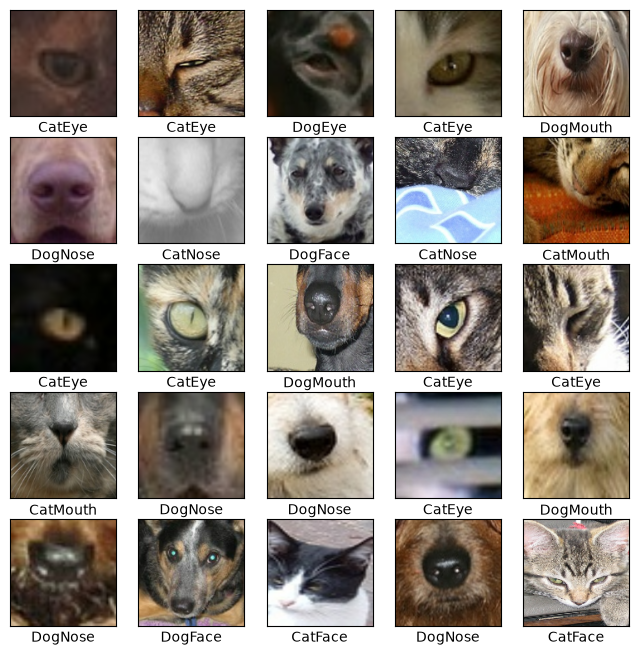

c:\Users\wah31\OneDrive\Documents\Data_Ai_Kaggle\venv\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 126, 126, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 28, 28, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 50176)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │     3,211,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 8)              │           520 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,268,168 (12.47 MB)

 Trainable params: 3,268,168 (12.47 MB)

 Non-trainable params: 0 (0.00 B)

c:\Users\wah31\OneDrive\Documents\Data_Ai_Kaggle\venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


Epoch 1/10
1592/1592 ━━━━━━━━━━━━━━━━━━━━ 255s 159ms/step - accuracy: 0.8487 - loss: 0.4545 - val_accuracy: 0.9373 - val_loss: 0.1973
Epoch 2/10
1592/1592 ━━━━━━━━━━━━━━━━━━━━ 264s 166ms/step - accuracy: 0.9527 - loss: 0.1432 - val_accuracy: 0.9451 - val_loss: 0.1804
Epoch 3/10
1592/1592 ━━━━━━━━━━━━━━━━━━━━ 259s 163ms/step - accuracy: 0.9686 - loss: 0.0934 - val_accuracy: 0.9473 - val_loss: 0.1880
Epoch 4/10
1592/1592 ━━━━━━━━━━━━━━━━━━━━ 264s 166ms/step - accuracy: 0.9784 - loss: 0.0644 - val_accuracy: 0.9513 - val_loss: 0.1869
Epoch 5/10
1592/1592 ━━━━━━━━━━━━━━━━━━━━ 260s 163ms/step - accuracy: 0.9839 - loss: 0.0472 - val_accuracy: 0.9567 - val_loss: 0.2010
Epoch 6/10
1592/1592 ━━━━━━━━━━━━━━━━━━━━ 273s 172ms/step - accuracy: 0.9871 - loss: 0.0376 - val_accuracy: 0.9564 - val_loss: 0.1956
Epoch 7/10
1592/1592 ━━━━━━━━━━━━━━━━━━━━ 277s 174ms/step - accuracy: 0.9878 - loss: 0.0342 - val_accuracy: 0.9483 - val_loss: 0.2205
Epoch 8/10
1592/1592 ━━━━━━━━━━━━━━━━━━━━ 7580s 145ms/step - a

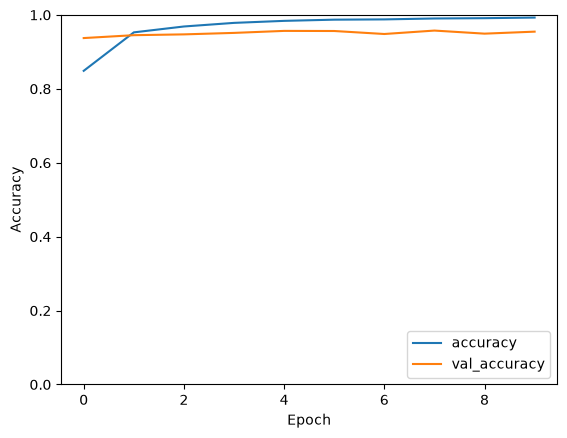

398/398 - 15s - 38ms/step - accuracy: 0.9547 - loss: 0.2553


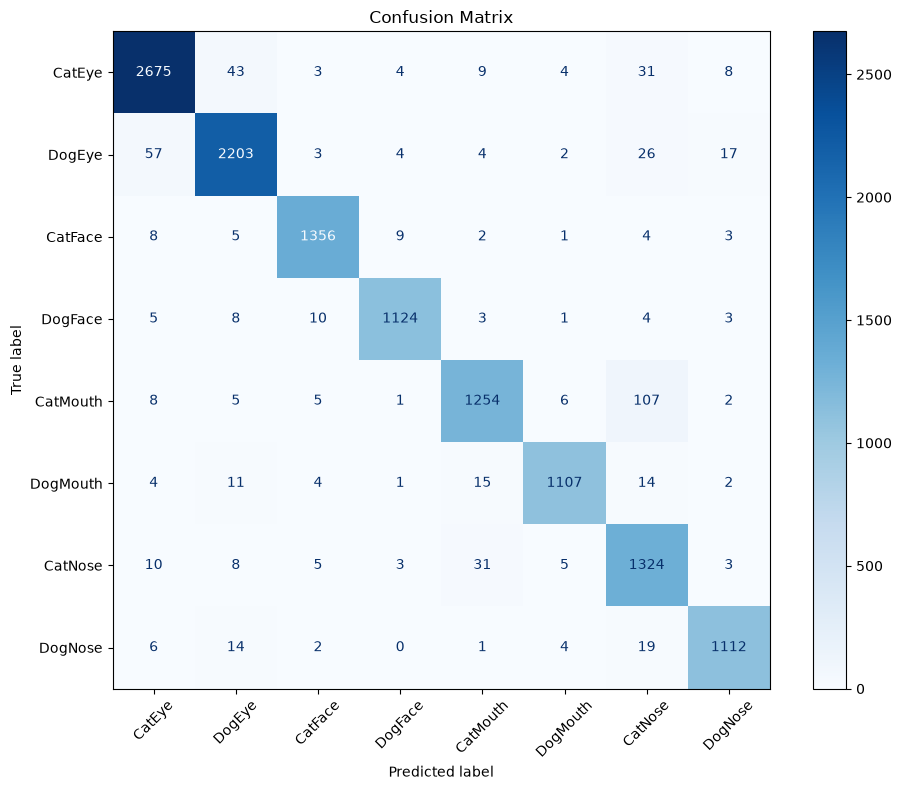


Classification Report:

              precision    recall  f1-score   support

      CatEye       0.96      0.96      0.96      2777
      DogEye       0.96      0.95      0.96      2316
     CatFace       0.98      0.98      0.98      1388
     DogFace       0.98      0.97      0.98      1158
    CatMouth       0.95      0.90      0.93      1388
    DogMouth       0.98      0.96      0.97      1158
     CatNose       0.87      0.95      0.91      1389
     DogNose       0.97      0.96      0.96      1158

    accuracy                           0.95     12732
   macro avg       0.96      0.95      0.95     12732
weighted avg       0.96      0.95      0.95     12732


ROC-AUC for Each Class:
CatEye: 0.9972
DogEye: 0.9978
CatFace: 0.9989
DogFace: 0.9993
CatMouth: 0.9956
DogMouth: 0.9990
CatNose: 0.9942
DogNose: 0.9990

Overall ROC-AUC (Macro OvR): 0.9976


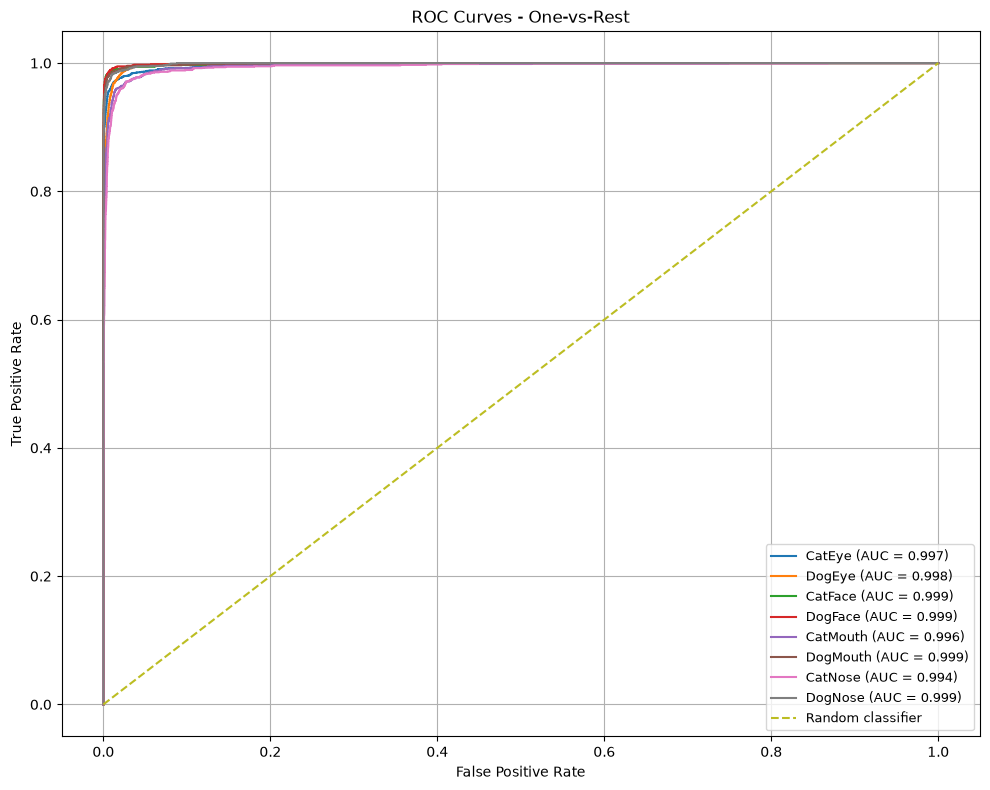

Test Accuracy is 0.9546810984611511


In [1]:
# Import TensorFlow
import tensorflow as tf
from tensorflow.keras import layers, models
import matplotlib.pyplot as plt

import os
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from tensorflow.keras.utils import load_img, img_to_array

from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report,
    roc_curve,
    auc,
    roc_auc_score
)
from sklearn.preprocessing import label_binarize

#Load Data set 

label_csv = r"C:\Users\wah31\OneDrive\Documents\Data_Ai_Kaggle\animal_facial_recognition\train_labels.csv"
training_images = r"C:\Users\wah31\OneDrive\Documents\Data_Ai_Kaggle\enge-707-2026-s-2-cat-and-dog-facial-feature-classification-ch\train\train"


df = pd.read_csv(label_csv, dtype={'image_id': str})

class_names = [
    'CatEye',
    'DogEye',
    'CatFace',
    'DogFace',
    'CatMouth',
    'DogMouth',
    'CatNose',
    'DogNose'
]

class_to_number = {
    name: i for i, name in enumerate(class_names)
}

df['label'] = df['class'].map(class_to_number)

train_df, test_df = train_test_split(
    df,
    test_size=0.2,
    random_state=123,
    stratify=df['label']
)

IMAGE_SIZE = (128, 128)

def load_image(image_id, label):
    image_path = tf.strings.join([
        training_images,
        os.sep,
        image_id,
        '.jpg'
    ])

    image = tf.io.read_file(image_path)
    image = tf.image.decode_jpeg(image, channels=3)
    image = tf.image.resize(image, IMAGE_SIZE)
    image = image / 255.0

    return image, label

train_dataset = tf.data.Dataset.from_tensor_slices(
    (
        train_df['image_id'].values,
        train_df['label'].values
    )
)

test_dataset = tf.data.Dataset.from_tensor_slices(
    (
        test_df['image_id'].values,
        test_df['label'].values
    )
)

train_dataset = train_dataset.map(
    load_image,
    num_parallel_calls=tf.data.AUTOTUNE
)

test_dataset = test_dataset.map(
    load_image,
    num_parallel_calls=tf.data.AUTOTUNE
)

BATCH_SIZE = 32

train_dataset = train_dataset.batch(BATCH_SIZE)
test_dataset = test_dataset.batch(BATCH_SIZE)

train_dataset = train_dataset.prefetch(tf.data.AUTOTUNE)
test_dataset = test_dataset.prefetch(tf.data.AUTOTUNE)

plt.figure(figsize=(8, 8))

for images, labels in train_dataset.take(1):
    for i in range(min(25, len(images))):
        plt.subplot(5, 5, i + 1)
        plt.xticks([])
        plt.yticks([])
        plt.grid(False)
        plt.imshow(images[i])
        plt.xlabel(class_names[labels[i]])

plt.show()


model = models.Sequential()
model.add(layers.Conv2D(
    32,
    (3, 3),
    activation='relu',
    input_shape=(128, 128, 3)
))
model.add(layers.MaxPooling2D((2, 2)))
model.add(layers.Conv2D(
    64,
    (3, 3),
    activation='relu'
))
model.add(layers.MaxPooling2D((2, 2)))
model.add(layers.Conv2D(
    64,
    (3, 3),
    activation='relu'
))
model.add(layers.Flatten())
model.add(layers.Dense(
    64,
    activation='relu'
))
model.add(layers.Dense(8))
model.summary()

model.compile(
    optimizer='adam',
    loss=tf.keras.losses.SparseCategoricalCrossentropy(
        from_logits=True
    ),
    metrics=['accuracy']
)

history = model.fit(
    train_dataset,
    epochs=10,
    validation_data=test_dataset
)

plt.plot(
    history.history['accuracy'],
    label='accuracy'
)

plt.plot(
    history.history['val_accuracy'],
    label='val_accuracy'
)

plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.ylim([0, 1])
plt.legend(loc='lower right')

plt.show()

test_loss, test_acc = model.evaluate(
    test_dataset,
    verbose=2
)
y_true = []
y_prob = []

for images, labels in test_dataset:
    logits = model.predict(
        images,
        verbose=0
    )

    probabilities = tf.nn.softmax(
        logits,
        axis=1
    )

    y_true.extend(labels.numpy())
    y_prob.extend(probabilities.numpy())

y_true = np.array(y_true)
y_prob = np.array(y_prob)

y_pred = np.argmax(
    y_prob,
    axis=1
)

cm = confusion_matrix(
    y_true,
    y_pred
)

fig, ax = plt.subplots(
    figsize=(10, 8)
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

disp.plot(
    ax=ax,
    cmap='Blues',
    xticks_rotation=45
)

plt.title('Confusion Matrix')
plt.tight_layout()
plt.show()

print('\nClassification Report:\n')

print(
    classification_report(
        y_true,
        y_pred,
        target_names=class_names
    )
)

y_true_bin = label_binarize(
    y_true,
    classes=np.arange(len(class_names))
)

print('\nROC-AUC for Each Class:')

for i, class_name in enumerate(class_names):
    class_auc = roc_auc_score(
        y_true_bin[:, i],
        y_prob[:, i]
    )

    print(
        f'{class_name}: {class_auc:.4f}'
    )

overall_auc = roc_auc_score(
    y_true_bin,
    y_prob,
    multi_class='ovr',
    average='macro'
)

print(
    f'\nOverall ROC-AUC (Macro OvR): {overall_auc:.4f}'
)

plt.figure(figsize=(10, 8))

for i, class_name in enumerate(class_names):
    fpr, tpr, _ = roc_curve(
        y_true_bin[:, i],
        y_prob[:, i]
    )

    class_auc = auc(
        fpr,
        tpr
    )

    plt.plot(
        fpr,
        tpr,
        label=f'{class_name} (AUC = {class_auc:.3f})'
    )

plt.plot(
    [0, 1],
    [0, 1],
    linestyle='--',
    label='Random classifier'
)

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curves - One-vs-Rest')

plt.legend(
    loc='lower right',
    fontsize=9
)

plt.grid()
plt.tight_layout()
plt.show()
print('Test Accuracy is', test_acc)


2 Epochs Base CNN (Tensorflow / Keras) 128x128 and normalized only (doesnt actually fix overfitting)

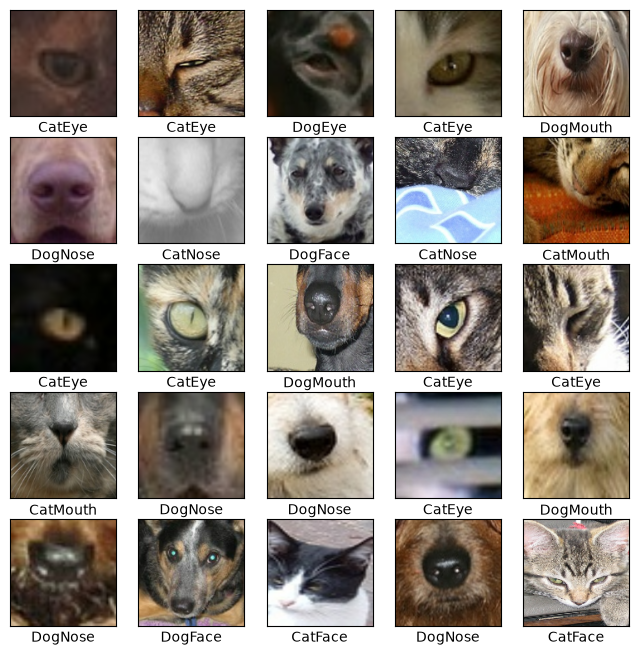

c:\Users\wah31\OneDrive\Documents\Data_Ai_Kaggle\venv\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_11"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_145 (Conv2D)             │ (None, 126, 126, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_14 (MaxPooling2D) │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_146 (Conv2D)             │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_15 (MaxPooling2D) │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_147 (Conv2D)             │ (None, 28, 28, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_8 (Flatten)             │ (None, 50176)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_18 (Dense)                │ (None, 64)             │     3,211,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_19 (Dense)                │ (None, 8)              │           520 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,268,168 (12.47 MB)

 Trainable params: 3,268,168 (12.47 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/2


c:\Users\wah31\OneDrive\Documents\Data_Ai_Kaggle\venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


1592/1592 ━━━━━━━━━━━━━━━━━━━━ 243s 152ms/step - accuracy: 0.8479 - loss: 0.4538 - val_accuracy: 0.9387 - val_loss: 0.1933
Epoch 2/2
1592/1592 ━━━━━━━━━━━━━━━━━━━━ 238s 149ms/step - accuracy: 0.9562 - loss: 0.1325 - val_accuracy: 0.9459 - val_loss: 0.1735


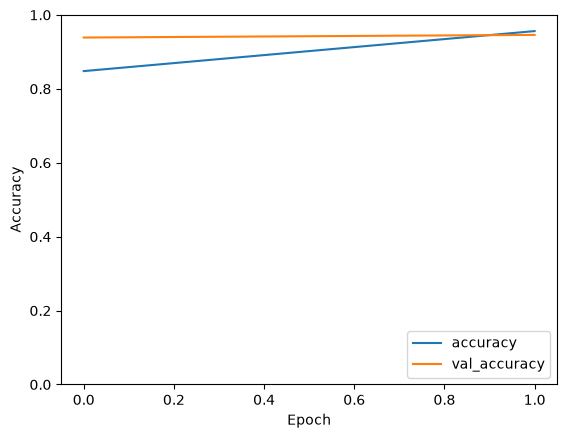

398/398 - 15s - 39ms/step - accuracy: 0.9459 - loss: 0.1735
Exported 689 misclassified images to misclassified_image_ids.csv


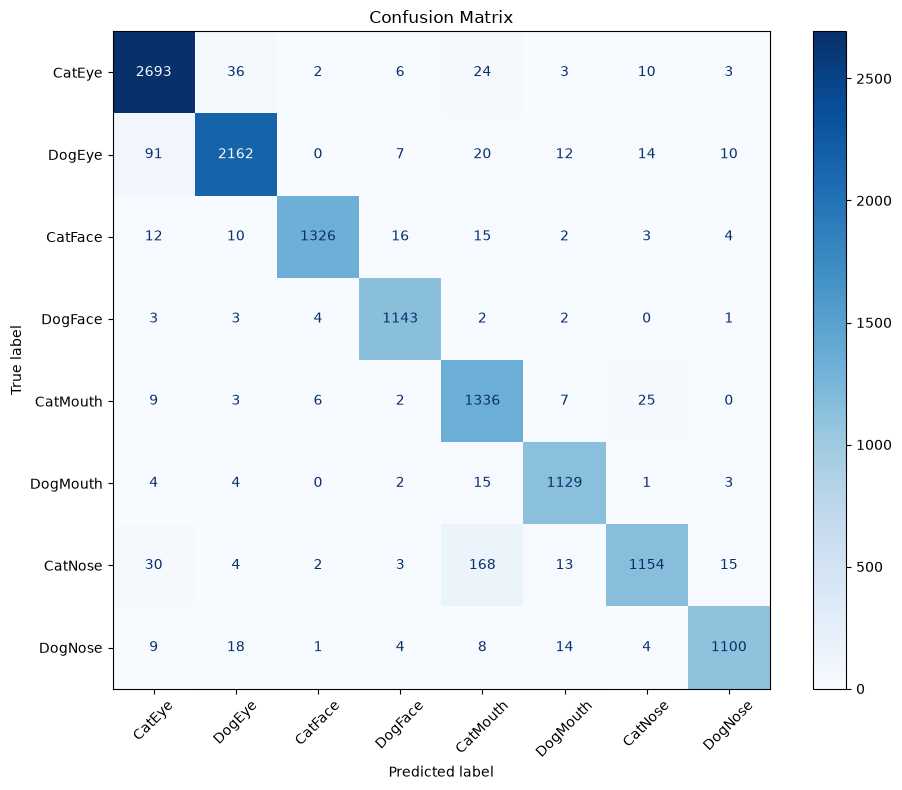


Classification Report:

              precision    recall  f1-score   support

      CatEye       0.94      0.97      0.96      2777
      DogEye       0.97      0.93      0.95      2316
     CatFace       0.99      0.96      0.97      1388
     DogFace       0.97      0.99      0.98      1158
    CatMouth       0.84      0.96      0.90      1388
    DogMouth       0.96      0.97      0.96      1158
     CatNose       0.95      0.83      0.89      1389
     DogNose       0.97      0.95      0.96      1158

    accuracy                           0.95     12732
   macro avg       0.95      0.95      0.95     12732
weighted avg       0.95      0.95      0.95     12732


ROC-AUC for Each Class:
CatEye: 0.9976
DogEye: 0.9980
CatFace: 0.9985
DogFace: 0.9996
CatMouth: 0.9959
DogMouth: 0.9991
CatNose: 0.9950
DogNose: 0.9990

Overall ROC-AUC (Macro OvR): 0.9979


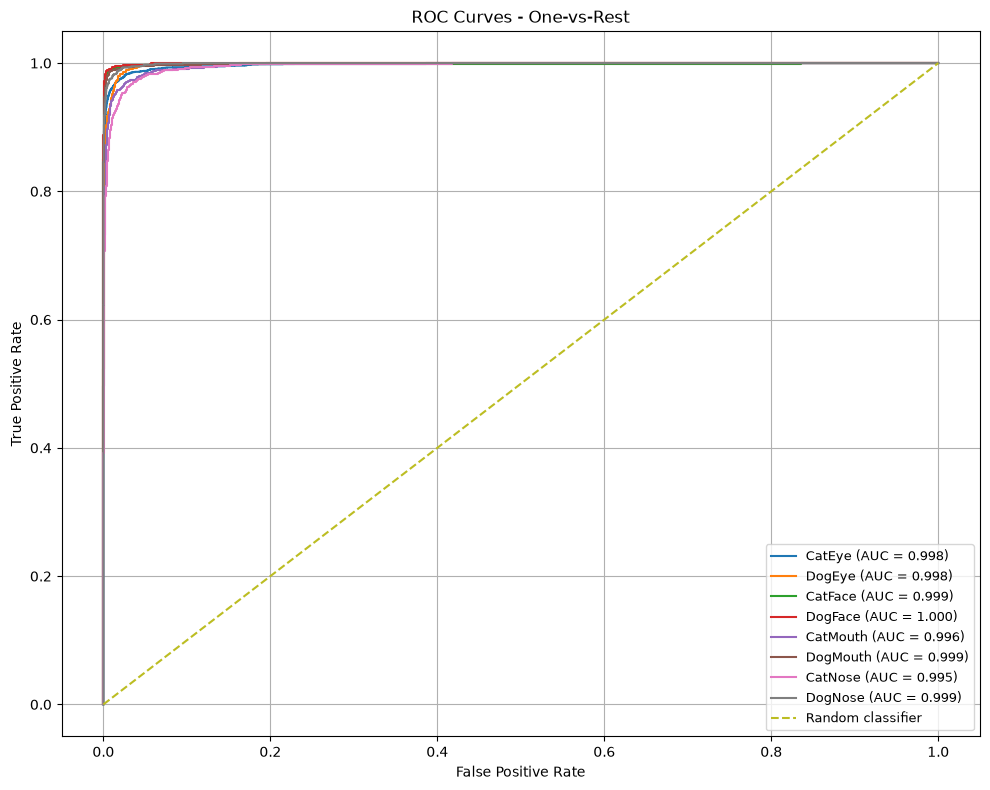

Test Accuracy is 0.9458844065666199


In [ ]:
# Import TensorFlow
import tensorflow as tf
from tensorflow.keras import layers, models
import matplotlib.pyplot as plt

import os
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from tensorflow.keras.utils import load_img, img_to_array

from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report,
    roc_curve,
    auc,
    roc_auc_score
)
from sklearn.preprocessing import label_binarize

#Load Data set 

label_csv = r"C:\Users\wah31\OneDrive\Documents\Data_Ai_Kaggle\animal_facial_recognition\train_labels.csv"
training_images = r"C:\Users\wah31\OneDrive\Documents\Data_Ai_Kaggle\enge-707-2026-s-2-cat-and-dog-facial-feature-classification-ch\train\train"


df = pd.read_csv(label_csv, dtype={'image_id': str})

class_names = [
    'CatEye',
    'DogEye',
    'CatFace',
    'DogFace',
    'CatMouth',
    'DogMouth',
    'CatNose',
    'DogNose'
]

class_to_number = {
    name: i for i, name in enumerate(class_names)
}

df['label'] = df['class'].map(class_to_number)

train_df, test_df = train_test_split(
    df,
    test_size=0.2,
    random_state=123,
    stratify=df['label']
)

IMAGE_SIZE = (128, 128)

def load_image(image_id, label):
    image_path = tf.strings.join([
        training_images,
        os.sep,
        image_id,
        '.jpg'
    ])

    image = tf.io.read_file(image_path)
    image = tf.image.decode_jpeg(image, channels=3)
    image = tf.image.resize(image, IMAGE_SIZE)
    image = image / 255.0

    return image, label

train_dataset = tf.data.Dataset.from_tensor_slices(
    (
        train_df['image_id'].values,
        train_df['label'].values
    )
)

test_dataset = tf.data.Dataset.from_tensor_slices(
    (
        test_df['image_id'].values,
        test_df['label'].values
    )
)

train_dataset = train_dataset.map(
    load_image,
    num_parallel_calls=tf.data.AUTOTUNE
)

test_dataset = test_dataset.map(
    load_image,
    num_parallel_calls=tf.data.AUTOTUNE
)

BATCH_SIZE = 32

train_dataset = train_dataset.batch(BATCH_SIZE)
test_dataset = test_dataset.batch(BATCH_SIZE)

train_dataset = train_dataset.prefetch(tf.data.AUTOTUNE)
test_dataset = test_dataset.prefetch(tf.data.AUTOTUNE)

plt.figure(figsize=(8, 8))

for images, labels in train_dataset.take(1):
    for i in range(min(25, len(images))):
        plt.subplot(5, 5, i + 1)
        plt.xticks([])
        plt.yticks([])
        plt.grid(False)
        plt.imshow(images[i])
        plt.xlabel(class_names[labels[i]])

plt.show()


model = models.Sequential()
model.add(layers.Conv2D(
    32,
    (3, 3),
    activation='relu',
    input_shape=(128, 128, 3)
))
model.add(layers.MaxPooling2D((2, 2)))
model.add(layers.Conv2D(
    64,
    (3, 3),
    activation='relu'
))
model.add(layers.MaxPooling2D((2, 2)))
model.add(layers.Conv2D(
    64,
    (3, 3),
    activation='relu'
))
model.add(layers.Flatten())
model.add(layers.Dense(
    64,
    activation='relu'
))
model.add(layers.Dense(8))
model.summary()

model.compile(
    optimizer='adam',
    loss=tf.keras.losses.SparseCategoricalCrossentropy(
        from_logits=True
    ),
    metrics=['accuracy']
)
EPOCHS = 2

history = model.fit(
    train_dataset,
    epochs= EPOCHS,
    validation_data=test_dataset
)

from datetime import datetime
timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")

model_save_path = (
    r"C:\Users\wah31\OneDrive\Documents\Data_Ai_Kaggle"
    r"\animal_facial_recognition\saved_models"
    rf"\CNN_Base_{EPOCHS}_{timestamp}.keras"
)


model.save(model_save_path)

plt.plot(
    history.history['accuracy'],
    label='accuracy'
)

plt.plot(
    history.history['val_accuracy'],
    label='val_accuracy'
)

plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.ylim([0, 1])
plt.legend(loc='lower right')

plt.show()

test_loss, test_acc = model.evaluate(
    test_dataset,
    verbose=2
)
y_true = []
y_prob = []

for images, labels in test_dataset:
    logits = model.predict(
        images,
        verbose=0
    )

    probabilities = tf.nn.softmax(
        logits,
        axis=1
    )

    y_true.extend(labels.numpy())
    y_prob.extend(probabilities.numpy())

y_true = np.array(y_true)
y_prob = np.array(y_prob)

y_pred = np.argmax(
    y_prob,
    axis=1
)


# Find misclassified images
misclassified_indices = np.where(y_true != y_pred)[0]

# Reset index so it matches y_true and y_pred
test_results = test_df.reset_index(drop=True)

# Create a DataFrame containing the misclassified images
misclassified_df = pd.DataFrame({
    'image_id': test_results.iloc[misclassified_indices]['image_id'].values,
    'true_label': [
        class_names[i] for i in y_true[misclassified_indices]
    ],
    'predicted_label': [
        class_names[i] for i in y_pred[misclassified_indices]
    ]
})

# Export to CSV
misclassified_df.to_csv(
    'misclassified_image_ids.csv',
    index=False
)

print(
    f"Exported {len(misclassified_df)} misclassified images "
    f"to misclassified_image_ids.csv"
)



cm = confusion_matrix(
    y_true,
    y_pred
)

fig, ax = plt.subplots(
    figsize=(10, 8)
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

disp.plot(
    ax=ax,
    cmap='Blues',
    xticks_rotation=45
)

plt.title('Confusion Matrix')
plt.tight_layout()
plt.show()

print('\nClassification Report:\n')

print(
    classification_report(
        y_true,
        y_pred,
        target_names=class_names
    )
)

y_true_bin = label_binarize(
    y_true,
    classes=np.arange(len(class_names))
)

print('\nROC-AUC for Each Class:')

for i, class_name in enumerate(class_names):
    class_auc = roc_auc_score(
        y_true_bin[:, i],
        y_prob[:, i]
    )

    print(
        f'{class_name}: {class_auc:.4f}'
    )

overall_auc = roc_auc_score(
    y_true_bin,
    y_prob,
    multi_class='ovr',
    average='macro'
)

print(
    f'\nOverall ROC-AUC (Macro OvR): {overall_auc:.4f}'
)

plt.figure(figsize=(10, 8))

for i, class_name in enumerate(class_names):
    fpr, tpr, _ = roc_curve(
        y_true_bin[:, i],
        y_prob[:, i]
    )

    class_auc = auc(
        fpr,
        tpr
    )

    plt.plot(
        fpr,
        tpr,
        label=f'{class_name} (AUC = {class_auc:.3f})'
    )

plt.plot(
    [0, 1],
    [0, 1],
    linestyle='--',
    label='Random classifier'
)

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curves - One-vs-Rest')

plt.legend(
    loc='lower right',
    fontsize=9
)

plt.grid()
plt.tight_layout()
plt.show()
print('Test Accuracy is', test_acc)


15 epochs early stopping & dropout to stop reliance on particular nnodes

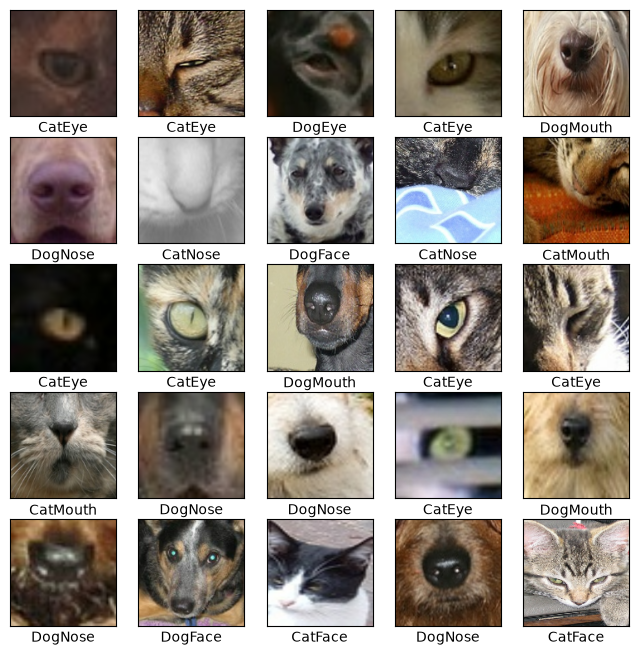

c:\Users\wah31\OneDrive\Documents\Data_Ai_Kaggle\venv\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_15"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential_14 (Sequential)      │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_151 (Conv2D)             │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_18 (MaxPooling2D) │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_152 (Conv2D)             │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_19 (MaxPooling2D) │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_153 (Conv2D)             │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_10 (Flatten)            │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_22 (Dense)                │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_23 (Dense)                │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

Epoch 1/15


c:\Users\wah31\OneDrive\Documents\Data_Ai_Kaggle\venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(
c:\Users\wah31\OneDrive\Documents\Data_Ai_Kaggle\venv\Lib\site-packages\keras\src\backend\tensorflow\ops\nn.py:1489: UserWarning: "`sparse_categorical_crossentropy` received `from_logits=True`, but the `output` argument was produced by a Softmax activation and thus does not represent logits. Was this intended?
  output, from_logits = _get_logits(


1592/1592 ━━━━━━━━━━━━━━━━━━━━ 250s 155ms/step - accuracy: 0.7606 - loss: 0.6785 - val_accuracy: 0.9156 - val_loss: 0.2598 - learning_rate: 0.0010
Epoch 2/15
1592/1592 ━━━━━━━━━━━━━━━━━━━━ 251s 158ms/step - accuracy: 0.8989 - loss: 0.3041 - val_accuracy: 0.9491 - val_loss: 0.1582 - learning_rate: 0.0010
Epoch 3/15
1592/1592 ━━━━━━━━━━━━━━━━━━━━ 247s 155ms/step - accuracy: 0.9225 - loss: 0.2391 - val_accuracy: 0.9477 - val_loss: 0.1596 - learning_rate: 0.0010
Epoch 4/15
1592/1592 ━━━━━━━━━━━━━━━━━━━━ 246s 155ms/step - accuracy: 0.9290 - loss: 0.2153 - val_accuracy: 0.9598 - val_loss: 0.1258 - learning_rate: 0.0010
Epoch 5/15
1592/1592 ━━━━━━━━━━━━━━━━━━━━ 270s 169ms/step - accuracy: 0.9362 - loss: 0.1956 - val_accuracy: 0.9607 - val_loss: 0.1261 - learning_rate: 0.0010
Epoch 6/15
1592/1592 ━━━━━━━━━━━━━━━━━━━━ 272s 171ms/step - accuracy: 0.9423 - loss: 0.1761 - val_accuracy: 0.9678 - val_loss: 0.1043 - learning_rate: 0.0010
Epoch 7/15
1592/1592 ━━━━━━━━━━━━━━━━━━━━ 290s 182ms/step - acc

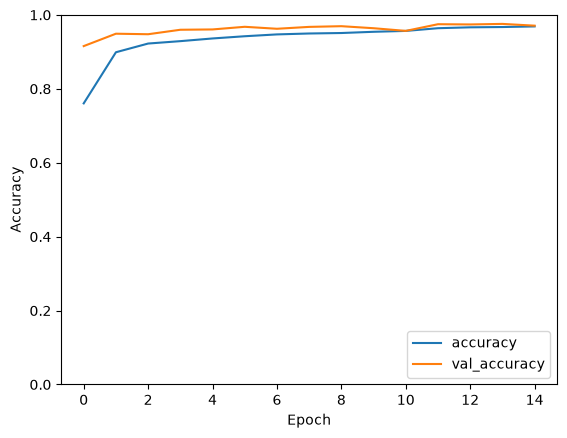

398/398 - 17s - 43ms/step - accuracy: 0.9757 - loss: 0.0802
Exported 310 misclassified images to misclassified_image_ids.csv


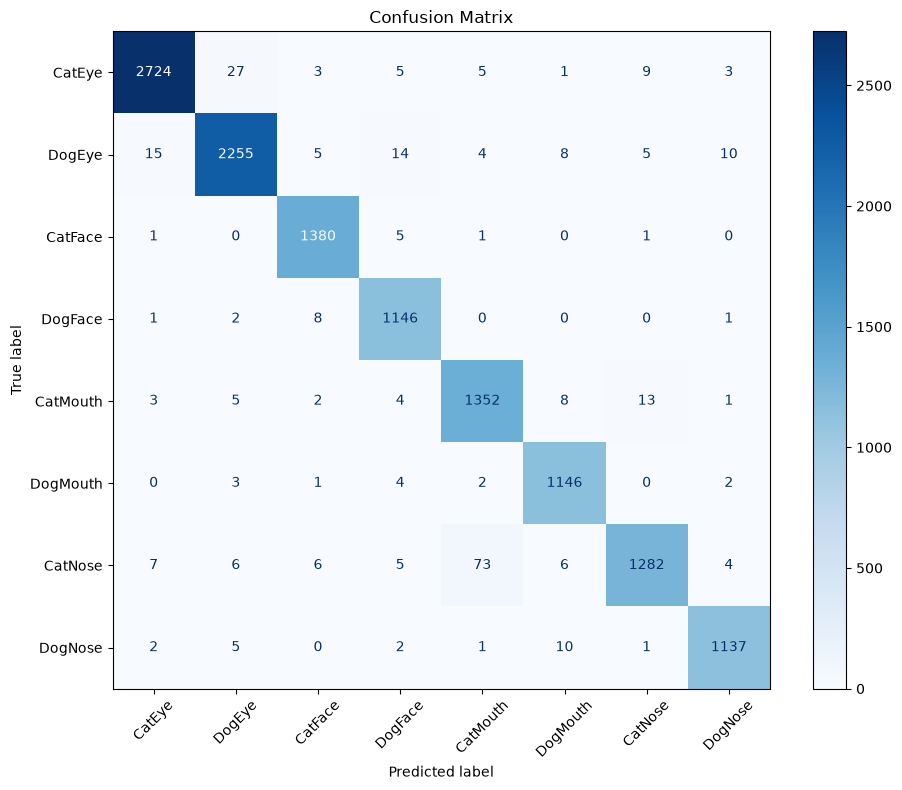


Classification Report:

              precision    recall  f1-score   support

      CatEye       0.99      0.98      0.99      2777
      DogEye       0.98      0.97      0.98      2316
     CatFace       0.98      0.99      0.99      1388
     DogFace       0.97      0.99      0.98      1158
    CatMouth       0.94      0.97      0.96      1388
    DogMouth       0.97      0.99      0.98      1158
     CatNose       0.98      0.92      0.95      1389
     DogNose       0.98      0.98      0.98      1158

    accuracy                           0.98     12732
   macro avg       0.97      0.98      0.97     12732
weighted avg       0.98      0.98      0.98     12732


ROC-AUC for Each Class:
CatEye: 0.9993
DogEye: 0.9993
CatFace: 0.9998
DogFace: 0.9995
CatMouth: 0.9989
DogMouth: 0.9997
CatNose: 0.9984
DogNose: 0.9996

Overall ROC-AUC (Macro OvR): 0.9993


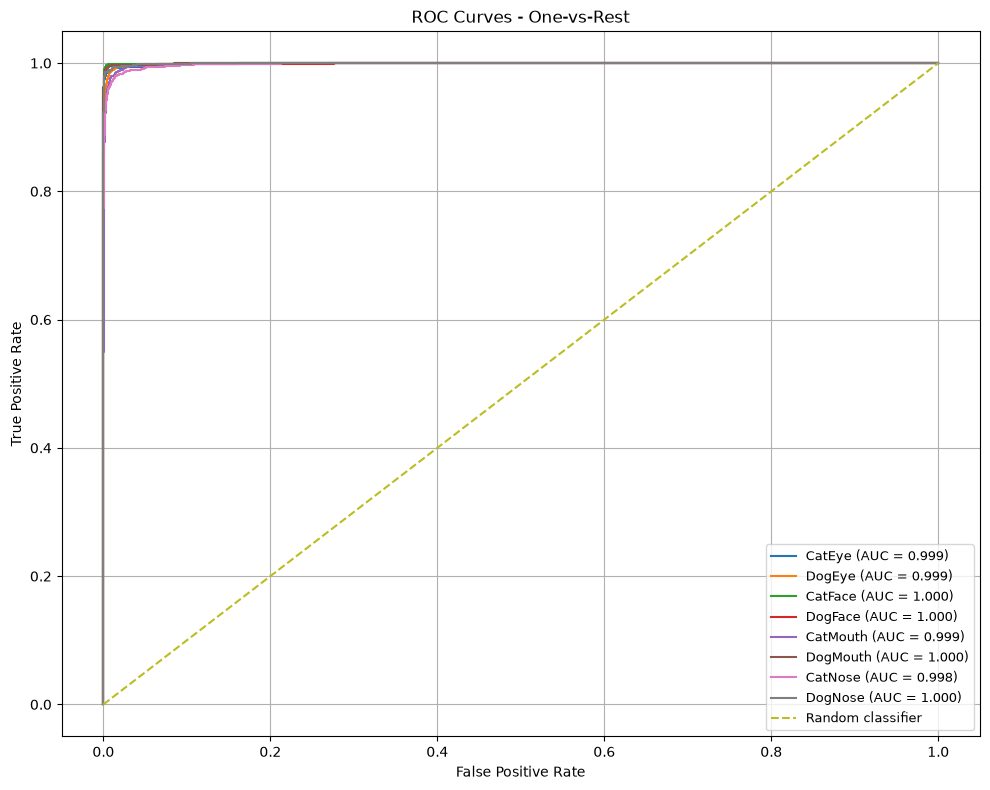

Test Accuracy is 0.9756519198417664


In [ ]:
# Import TensorFlow
import tensorflow as tf
from tensorflow.keras import layers, models
import matplotlib.pyplot as plt

import os
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from tensorflow.keras.utils import load_img, img_to_array

from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report,
    roc_curve,
    auc,
    roc_auc_score
)
from sklearn.preprocessing import label_binarize

#Load Data set 

label_csv = r"C:\Users\wah31\OneDrive\Documents\Data_Ai_Kaggle\animal_facial_recognition\train_labels.csv"
training_images = r"C:\Users\wah31\OneDrive\Documents\Data_Ai_Kaggle\enge-707-2026-s-2-cat-and-dog-facial-feature-classification-ch\train\train"


df = pd.read_csv(label_csv, dtype={'image_id': str})

class_names = [
    'CatEye',
    'DogEye',
    'CatFace',
    'DogFace',
    'CatMouth',
    'DogMouth',
    'CatNose',
    'DogNose'
]

class_to_number = {
    name: i for i, name in enumerate(class_names)
}

df['label'] = df['class'].map(class_to_number)

train_df, test_df = train_test_split(
    df,
    test_size=0.2,
    random_state=123,
    stratify=df['label']
)

IMAGE_SIZE = (128, 128)

def load_image(image_id, label):
    image_path = tf.strings.join([
        training_images,
        os.sep,
        image_id,
        '.jpg'
    ])

    image = tf.io.read_file(image_path)
    image = tf.image.decode_jpeg(image, channels=3)
    image = tf.image.resize(image, IMAGE_SIZE)
    image = image / 255.0

    return image, label

train_dataset = tf.data.Dataset.from_tensor_slices(
    (
        train_df['image_id'].values,
        train_df['label'].values
    )
)

test_dataset = tf.data.Dataset.from_tensor_slices(
    (
        test_df['image_id'].values,
        test_df['label'].values
    )
)

train_dataset = train_dataset.map(
    load_image,
    num_parallel_calls=tf.data.AUTOTUNE
)

test_dataset = test_dataset.map(
    load_image,
    num_parallel_calls=tf.data.AUTOTUNE
)

BATCH_SIZE = 32

train_dataset = train_dataset.batch(BATCH_SIZE)
test_dataset = test_dataset.batch(BATCH_SIZE)

train_dataset = train_dataset.prefetch(tf.data.AUTOTUNE)
test_dataset = test_dataset.prefetch(tf.data.AUTOTUNE)

plt.figure(figsize=(8, 8))

for images, labels in train_dataset.take(1):
    for i in range(min(25, len(images))):
        plt.subplot(5, 5, i + 1)
        plt.xticks([])
        plt.yticks([])
        plt.grid(False)
        plt.imshow(images[i])
        plt.xlabel(class_names[labels[i]])

plt.show()

data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.05),
    layers.RandomZoom(0.1),
    layers.RandomContrast(0.1),
])


model = models.Sequential([

    data_augmentation,
    layers.Conv2D(32,(3, 3),activation='relu',input_shape=(128, 128, 3)),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64,(3, 3),activation='relu'),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64,(3, 3),activation='relu'),

    layers.Flatten(),
    layers.Dense(64,activation='relu'),
    layers.Dropout(0.3),

    layers.Dense(8, activation='softmax')
])

model.summary()

model.compile(
    optimizer='adam',
    loss=tf.keras.losses.SparseCategoricalCrossentropy(
        from_logits=False
    ),
    metrics=['accuracy']
)

callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor='val_loss',
        patience=3,
        restore_best_weights=True
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor='val_loss',
        factor=0.5,
        patience=2,
        min_lr=1e-6
    )
]

EPOCHS = 30

history = model.fit(
    train_dataset,
    epochs= EPOCHS,
    validation_data=test_dataset,
    callbacks =callbacks
)

from datetime import datetime
timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")

model_save_path = (
    r"C:\Users\wah31\OneDrive\Documents\Data_Ai_Kaggle"
    r"\animal_facial_recognition\saved_models"
    rf"\CNN_Base_{EPOCHS}_{timestamp}.keras"
)


model.save(model_save_path)

plt.plot(
    history.history['accuracy'],
    label='accuracy'
)

plt.plot(
    history.history['val_accuracy'],
    label='val_accuracy'
)

plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.ylim([0, 1])
plt.legend(loc='lower right')

plt.show()

test_loss, test_acc = model.evaluate(
    test_dataset,
    verbose=2
)
y_true = []
y_prob = []

for images, labels in test_dataset:

    probabilities =  model.predict(images, verbose=0)

    y_true.extend(labels.numpy())
    y_prob.extend(probabilities.numpy())

y_true = np.array(y_true)
y_prob = np.array(y_prob)

y_pred = np.argmax(
    y_prob,
    axis=1
)


# Find misclassified images
misclassified_indices = np.where(y_true != y_pred)[0]

# Reset index so it matches y_true and y_pred
test_results = test_df.reset_index(drop=True)

# Create a DataFrame containing the misclassified images
misclassified_df = pd.DataFrame({
    'image_id': test_results.iloc[misclassified_indices]['image_id'].values,
    'true_label': [
        class_names[i] for i in y_true[misclassified_indices]
    ],
    'predicted_label': [
        class_names[i] for i in y_pred[misclassified_indices]
    ]
})

# Export to CSV
misclassified_df.to_csv(
    'misclassified_image_ids.csv',
    index=False
)

print(
    f"Exported {len(misclassified_df)} misclassified images "
    f"to misclassified_image_ids.csv"
)



cm = confusion_matrix(
    y_true,
    y_pred
)

fig, ax = plt.subplots(
    figsize=(10, 8)
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

disp.plot(
    ax=ax,
    cmap='Blues',
    xticks_rotation=45
)

plt.title('Confusion Matrix')
plt.tight_layout()
plt.show()

print('\nClassification Report:\n')

print(
    classification_report(
        y_true,
        y_pred,
        target_names=class_names
    )
)

y_true_bin = label_binarize(
    y_true,
    classes=np.arange(len(class_names))
)

print('\nROC-AUC for Each Class:')

for i, class_name in enumerate(class_names):
    class_auc = roc_auc_score(
        y_true_bin[:, i],
        y_prob[:, i]
    )

    print(
        f'{class_name}: {class_auc:.4f}'
    )

overall_auc = roc_auc_score(
    y_true_bin,
    y_prob,
    multi_class='ovr',
    average='macro'
)

print(
    f'\nOverall ROC-AUC (Macro OvR): {overall_auc:.4f}'
)

plt.figure(figsize=(10, 8))

for i, class_name in enumerate(class_names):
    fpr, tpr, _ = roc_curve(
        y_true_bin[:, i],
        y_prob[:, i]
    )

    class_auc = auc(
        fpr,
        tpr
    )

    plt.plot(
        fpr,
        tpr,
        label=f'{class_name} (AUC = {class_auc:.3f})'
    )

plt.plot(
    [0, 1],
    [0, 1],
    linestyle='--',
    label='Random classifier'
)

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curves - One-vs-Rest')

plt.legend(
    loc='lower right',
    fontsize=9
)

plt.grid()
plt.tight_layout()
plt.show()
print('Test Accuracy is', test_acc)


Run model on test data

In [ ]:
import tensorflow as tf
import numpy as np
import os
import pandas as pd
from tqdm import tqdm

model_path = r"C:\Users\wah31\OneDrive\Documents\Data_Ai_Kaggle\animal_facial_recognition\saved_models\CNN_Base_15_20261006_185917.keras"

test_folder = r"C:\Users\wah31\OneDrive\Documents\Data_Ai_Kaggle\enge-707-2026-s-2-cat-and-dog-facial-feature-classification-ch\test\test"

model = tf.keras.models.load_model(model_path)

print("Model loaded successfully!")

BATCH_SIZE = 64


def classify_folder(folder_path):

    results = []

    filenames = [
        filename
        for filename in os.listdir(folder_path)
        if filename.lower().endswith(
            ('.jpg', '.jpeg', '.png')
        )
    ]

    for i in tqdm(
        range(0, len(filenames), BATCH_SIZE),
        desc="Classifying images",
        unit="batch"
    ):

        batch_filenames = filenames[i:i + BATCH_SIZE]

        images = []

        for filename in batch_filenames:

            image_path = os.path.join(
                folder_path,
                filename
            )

            image = tf.io.read_file(image_path)

            image = tf.image.decode_image(
                image,
                channels=3,
                expand_animations=False
            )

            image = tf.image.resize(
                image,
                IMAGE_SIZE
            )

            image = image / 255.0

            images.append(image)

        images = tf.stack(images)

        # Predict entire batch at once
        probabilities = model.predict(
            images,
            verbose=0
        )

        for filename, probability in zip(
            batch_filenames,
            probabilities
        ):

            predicted_index = np.argmax(probability)

            predicted_class = class_names[
                predicted_index
            ]

            confidence = probability[
                predicted_index
            ]

            results.append({
                'image_id': filename,
                'class': predicted_class,
                # 'confidence': confidence
            })

    results_df = pd.DataFrame(results)

    model_name = os.path.basename(model_path)
    output_folder = r"C:\Users\wah31\OneDrive\Documents\Data_Ai_Kaggle\animal_facial_recognition\test_results"
    output_path = os.path.join(
    output_folder,
    model_name.replace(".keras", "_results.csv")
    )

    results_df.to_csv(
        output_path,
        index=False
    )
    

    return results_df


classify_folder(test_folder)

Model loaded successfully!


Classifying images: 100%|██████████| 461/461 [02:11<00:00,  3.50batch/s]


,image_id,class,confidence,CatEye_prob,DogEye_prob,CatFace_prob,DogFace_prob,CatMouth_prob,DogMouth_prob,CatNose_prob,DogNose_prob
0,00001.jpg,DogEye,0.999997,2.750691e-06,9.999973e-01,4.531350e-11,1.375783e-10,1.975025e-12,7.297007e-11,4.445777e-10,1.883420e-09
1,00002.jpg,DogMouth,0.988035,3.848460e-07,2.146621e-05,1.245838e-08,2.130149e-05,1.001350e-04,9.880354e-01,1.464477e-03,1.035693e-02
2,00003.jpg,DogNose,0.999792,8.743991e-09,3.109590e-08,3.120999e-08,4.303088e-05,7.020063e-08,1.530944e-04,1.144456e-05,9.997923e-01
3,00004.jpg,DogFace,0.999856,2.176145e-13,6.710131e-15,1.444374e-04,9.998555e-01,1.462745e-10,1.006703e-14,8.364562e-13,1.409178e-15
4,00005.jpg,CatMouth,0.999974,4.563057e-12,2.293739e-21,8.020505e-16,1.014488e-20,9.999744e-01,9.372329e-19,2.568195e-05,4.587191e-21
...,...,...,...,...,...,...,...,...,...,...,...
29438,29439.jpg,CatMouth,0.490195,1.321433e-02,5.335810e-02,1.654254e-03,7.869624e-04,4.901948e-01,1.568034e-02,3.996256e-01,2.548560e-02
29439,29440.jpg,CatMouth,0.645244,7.938124e-04,7.447781e-07,9.026680e-07,7.044555e-09,6.452438e-01,5.099486e-05,3.538950e-01,1.482633e-05
29440,29441.jpg,DogFace,0.999983,8.621849e-10,5.912953e-08,1.707369e-05,9.999830e-01,6.005341e-10,2.379605e-10,3.197460e-09,3.850458e-12
29441,29442.jpg,DogFace,1.000000,7.027517e-14,5.430941e-14,7.070346e-08,9.999999e-01,8.948845e-15,3.158426e-15,1.034597e-14,1.531007e-16


Strip .jpg from output csv

In [ ]:
import pandas as pd
import os

# Input CSV
input_file = r"C:\Users\wah31\OneDrive\Documents\Data_Ai_Kaggle\animal_facial_recognition\test_results\CNN_Base_15_20261006_185917_results.csv"

# Output CSV
output_file = r"C:\Users\wah31\OneDrive\Documents\Data_Ai_Kaggle\animal_facial_recognition\test_results\CNN_Base_15_20261006_185917_results_clean.csv"


# Load CSV
df = pd.read_csv(input_file)

# Remove .jpg from the first column
df.iloc[:, 0] = (
    df.iloc[:, 0]
    .astype(str)
    .str.replace(r'\.jpg$', '', regex=True)
)

# Save cleaned CSV
df.to_csv(output_file, index=False)

print("Done!")
print("Saved to:")
print(output_file)

Done!
Saved to:
C:\Users\wah31\OneDrive\Documents\Data_Ai_Kaggle\animal_facial_recognition\test_results\CNN_Base_15_20261006_185917_results_clean.csv


RESNET (too computationally expensive EST 400hrs on cpu)

In [ ]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras.layers import Dense, Conv2D, BatchNormalization, Activation
from tensorflow.keras.layers import AveragePooling2D, Input, Flatten, Add
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import ModelCheckpoint, LearningRateScheduler, ReduceLROnPlateau
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.regularizers import l2
from tensorflow.keras.models import Model

import numpy as np
import os
import importlib

import image_preprocessing
importlib.reload(image_preprocessing)


batch_size = 32
epochs = 200
data_augmentation = True
num_classes = 8
subtract_pixel_mean = True


version = 2
n = 3
depth = n * 9 + 2

model_type = 'ResNet %dv%d' % (depth, version)

train_dataset, validation_dataset = image_preprocessing.preprocessTrainingData()

def lr_schedule(epoch):
    lr = 1e-3
    if epoch > 180:
        lr *= 0.5e-3
    elif epoch > 160:
        lr *= 1e-3
    elif epoch > 120:
        lr *= 1e-2
    elif epoch > 80:
        lr *= 1e-1
    print('Learning rate:', lr)
    return lr


def resnet_layer(inputs,
                 num_filters=16,
                 kernel_size=3,
                 strides=1,
                 activation='relu',
                 batch_normalization=True,
                 conv_first=True):
    conv = Conv2D(num_filters,
                  kernel_size=kernel_size,
                  strides=strides,
                  padding='same',
                  kernel_initializer='he_normal',
                  kernel_regularizer=l2(1e-4))
    x = inputs
    if conv_first:
        x = conv(x)
        if batch_normalization:
            x = BatchNormalization()(x)
        if activation is not None:
            x = Activation(activation)(x)
    else:
        if batch_normalization:
            x = BatchNormalization()(x)
        if activation is not None:
            x = Activation(activation)(x)
        x = conv(x)
    return x

input_shape = (128, 128, 3)

def resnet_v2(input_shape, depth, num_classes=8):
    if (depth - 2) % 9 != 0:
        raise ValueError('depth should be 9n + 2')

    data_augmentation = keras.Sequential([
    keras.layers.RandomFlip("horizontal"),
    keras.layers.RandomRotation(0.1),
    keras.layers.RandomZoom(0.1),
    ])  

    num_filters_in = 16
    num_res_blocks = int((depth - 2) / 9)
    inputs = Input(shape=input_shape)
    x = data_augmentation(inputs)
    x = resnet_layer(x, num_filters=num_filters_in, conv_first=True)

    

    for stage in range(3):
        for res_block in range(num_res_blocks):
            activation = 'relu'
            batch_normalization = True
            strides = 1
            if stage == 0:
                num_filters_out = num_filters_in * 4
                if res_block == 0:
                    activation = None
                    batch_normalization = False
            else:
                num_filters_out = num_filters_in * 2
                if res_block == 0:
                    strides = 2
            y = resnet_layer(x, num_filters=num_filters_in, kernel_size=1,
                             strides=strides, activation=activation,
                             batch_normalization=batch_normalization, conv_first=False)
            y = resnet_layer(y, num_filters=num_filters_in, conv_first=False)
            y = resnet_layer(y, num_filters=num_filters_out, kernel_size=1, conv_first=False)
            if res_block == 0:
                x = resnet_layer(x, num_filters=num_filters_out, kernel_size=1,
                                 strides=strides, activation=None, batch_normalization=False)
            x = Add()([x, y])
        num_filters_in = num_filters_out

    x = BatchNormalization()(x)
    x = Activation('relu')(x)
    x = keras.layers.GlobalAveragePooling2D()(x)
    outputs = Dense(
        num_classes,
        activation='softmax',
        kernel_initializer='he_normal'
    )(x)
    model = Model(inputs=inputs, outputs=outputs)
    return model


model = resnet_v2(input_shape=input_shape, depth=depth, num_classes=num_classes)


model.compile(loss='sparse_categorical_crossentropy',
              optimizer=Adam(learning_rate=lr_schedule(0)),
              metrics=['accuracy'])
model.summary()

history = model.fit(
    train_dataset,
    epochs = epochs,
    validation_data = validation_dataset,
    callbacks=callbacks
)

save_dir = os.path.join(os.getcwd(), 'saved_models')
model_name = 'cifar10_%s_model.{epoch:03d}.keras' % model_type
os.makedirs(save_dir, exist_ok=True)
filepath = os.path.join(save_dir, model_name)

checkpoint = ModelCheckpoint(filepath=filepath,
                             monitor='val_accuracy',
                             verbose=1,
                             save_best_only=True)
lr_scheduler = LearningRateScheduler(lr_schedule)
lr_reducer = ReduceLROnPlateau(factor=np.sqrt(0.1), cooldown=0, patience=5, min_lr=0.5e-6)
callbacks = [checkpoint, lr_reducer, lr_scheduler]



ViT-B

In [16]:
#PREPROCESSING FOR VIT

import os
import pandas as pd
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader, TensorDataset
from torchvision.models import vit_b_32, ViT_B_32_Weights
from sklearn.model_selection import train_test_split
from PIL import Image
from tqdm import tqdm

label_csv = r"C:\Users\wah31\OneDrive\Documents\Data_Ai_Kaggle\animal_facial_recognition\train_labels.csv"

training_images = r"C:\Users\wah31\OneDrive\Documents\Data_Ai_Kaggle\enge-707-2026-s-2-cat-and-dog-facial-feature-classification-ch\train\train"

class_names = [
    'CatEye',
    'DogEye',
    'CatFace',
    'DogFace',
    'CatMouth',
    'DogMouth',
    'CatNose',
    'DogNose'
]

class_to_number = {
    name: i for i, name in enumerate(class_names)
}

df = pd.read_csv(
    label_csv,
    dtype={'image_id': str}
)

df['label'] = df['class'].map(class_to_number)

train_df, val_df = train_test_split(
    df,
    test_size=0.2,
    random_state=123,
    stratify=df['label']
)

weights = ViT_B_32_Weights.DEFAULT

transform = weights.transforms()

class AnimalDataset(Dataset):

    def __init__(
        self,
        dataframe,
        image_dir,
        transform=None
    ):
        self.dataframe = dataframe.reset_index(drop=True)
        self.image_dir = image_dir
        self.transform = transform

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, idx):

        image_id = self.dataframe.loc[idx, 'image_id']

        label = self.dataframe.loc[idx, 'label']

        image_path = os.path.join(
            self.image_dir,
            image_id + ".jpg"
        )

        image = Image.open(
            image_path
        ).convert("RGB")

        if self.transform:
            image = self.transform(image)

        return (
            image,
            torch.tensor(
                label,
                dtype=torch.long
            )
        )

train_dataset = AnimalDataset(
    train_df,
    training_images,
    transform=transform
)

val_dataset = AnimalDataset(
    val_df,
    training_images,
    transform=transform
)

batch_size = 16

train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=False,
    num_workers=0
)

val_loader = DataLoader(
    val_dataset,
    batch_size=batch_size,
    shuffle=False,
    num_workers=0
)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Using device:", device)

model = vit_b_32(
    weights=weights
)

model.eval()

for param in model.parameters():
    param.requires_grad = False

model = model.to(device)

print("Extracting training features...")

train_features = []
train_labels = []

with torch.no_grad():

    for inputs, labels in tqdm(
        train_loader,
        desc="Training features"
    ):

        inputs = inputs.to(device)

        features = model._process_input(inputs)

        n = features.shape[0]

        batch_class_token = model.class_token.expand(
            n,
            -1,
            -1
        )

        features = torch.cat(
            [batch_class_token, features],
            dim=1
        )

        features = model.encoder(features)

        features = features[:, 0]

        train_features.append(
            features.cpu()
        )

        train_labels.append(
            labels
        )

train_features = torch.cat(
    train_features
)

train_labels = torch.cat(
    train_labels
)

print("Training features:", train_features.shape)

print("Extracting validation features...")

val_features = []
val_labels = []

with torch.no_grad():

    for inputs, labels in tqdm(
        val_loader,
        desc="Validation features"
    ):

        inputs = inputs.to(device)

        features = model._process_input(inputs)

        n = features.shape[0]

        batch_class_token = model.class_token.expand(
            n,
            -1,
            -1
        )

        features = torch.cat(
            [batch_class_token, features],
            dim=1
        )

        features = model.encoder(features)

        features = features[:, 0]

        val_features.append(
            features.cpu()
        )

        val_labels.append(
            labels
        )

val_features = torch.cat(
    val_features
)

val_labels = torch.cat(
    val_labels
)

print("Validation features:", val_features.shape)

feature_dataset = TensorDataset(
    train_features,
    train_labels
)

val_feature_dataset = TensorDataset(
    val_features,
    val_labels
)

feature_loader = DataLoader(
    feature_dataset,
    batch_size=64,
    shuffle=True
)

val_feature_loader = DataLoader(
    val_feature_dataset,
    batch_size=64,
    shuffle=False
)

classifier = nn.Linear(
    train_features.shape[1],
    8
)

classifier = classifier.to(device)

criterion = nn.CrossEntropyLoss()

optimizer = optim.AdamW(
    classifier.parameters(),
    lr=1e-3,
    weight_decay=1e-4
)

num_epochs = 30

best_val_accuracy = 0.0

patience = 5

epochs_without_improvement = 0

for epoch in range(num_epochs):

    classifier.train()

    running_loss = 0.0

    correct = 0

    total = 0

    for features, labels in tqdm(
        feature_loader,
        desc=f"Epoch {epoch+1}/{num_epochs} Training"
    ):

        features = features.to(device)

        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = classifier(features)

        loss = criterion(
            outputs,
            labels
        )

        loss.backward()

        optimizer.step()

        running_loss += loss.item()

        _, predicted = torch.max(
            outputs,
            1
        )

        total += labels.size(0)

        correct += (
            predicted == labels
        ).sum().item()

    train_loss = (
        running_loss /
        len(feature_loader)
    )

    train_accuracy = (
        correct /
        total
    )

    classifier.eval()

    val_loss = 0.0

    val_correct = 0

    val_total = 0

    with torch.no_grad():

        for features, labels in tqdm(
            val_feature_loader,
            desc=f"Epoch {epoch+1}/{num_epochs} Validation"
        ):

            features = features.to(device)

            labels = labels.to(device)

            outputs = classifier(features)

            loss = criterion(
                outputs,
                labels
            )

            val_loss += loss.item()

            _, predicted = torch.max(
                outputs,
                1
            )

            val_total += labels.size(0)

            val_correct += (
                predicted == labels
            ).sum().item()

    val_loss = (
        val_loss /
        len(val_feature_loader)
    )

    val_accuracy = (
        val_correct /
        val_total
    )

    print(
        f"Epoch [{epoch+1}/{num_epochs}] "
        f"Train Loss: {train_loss:.4f} "
        f"Train Acc: {train_accuracy:.4f} "
        f"Val Loss: {val_loss:.4f} "
        f"Val Acc: {val_accuracy:.4f}"
    )

    if val_accuracy > best_val_accuracy:

        best_val_accuracy = val_accuracy

        epochs_without_improvement = 0

        torch.save(
            classifier.state_dict(),
            "best_vit_b32_classifier.pth"
        )

        print(
            f"  --> Best model saved! "
            f"Val Acc: {val_accuracy:.4f}"
        )

    else:

        epochs_without_improvement += 1

        print(
            f"  --> No improvement "
            f"({epochs_without_improvement}/{patience})"
        )

    if epochs_without_improvement >= patience:

        print(
            "Early stopping triggered."
        )

        break

Using device: cpu
Extracting training features...


Training features: 100%|██████████| 3183/3183 [41:34<00:00,  1.28it/s]


Training features: torch.Size([50928, 768])
Extracting validation features...


Validation features: 100%|██████████| 796/796 [10:23<00:00,  1.28it/s]


Validation features: torch.Size([12732, 768])


...

Epoch [16/30] Train Loss: 0.2119 Train Acc: 0.9043 Val Loss: 0.2590 Val Acc: 0.8787
  --> No improvement (3/5)


Epoch 17/30 Validation: 100%|██████████| 199/199 [00:00<00:00, 961.25it/s]


Epoch [17/30] Train Loss: 0.2108 Train Acc: 0.9040 Val Loss: 0.2547 Val Acc: 0.8810
  --> No improvement (4/5)


Epoch 18/30 Validation: 100%|██████████| 199/199 [00:00<00:00, 960.78it/s]

Epoch [18/30] Train Loss: 0.2108 Train Acc: 0.9047 Val Loss: 0.2612 Val Acc: 0.8782
  --> No improvement (5/5)
Early stopping triggered.


In [1]:
#VIT with accuracy outputs
import os
import pandas as pd
import numpy as np

import torch
import torch.nn as nn
import torch.optim as optim

from torch.utils.data import Dataset, DataLoader, TensorDataset

from torchvision.models import vit_b_32, ViT_B_32_Weights

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

from PIL import Image
from tqdm import tqdm


label_csv = r"C:\Users\wah31\OneDrive\Documents\Data_Ai_Kaggle\animal_facial_recognition\train_labels.csv"

training_images = r"C:\Users\wah31\OneDrive\Documents\Data_Ai_Kaggle\enge-707-2026-s-2-cat-and-dog-facial-feature-classification-ch\train\train"


class_names = [
    'CatEye',
    'DogEye',
    'CatFace',
    'DogFace',
    'CatMouth',
    'DogMouth',
    'CatNose',
    'DogNose'
]

num_classes = len(class_names)

class_to_number = {
    name: i for i, name in enumerate(class_names)
}


df = pd.read_csv(
    label_csv,
    dtype={'image_id': str}
)

df['label'] = df['class'].map(class_to_number)


if df['label'].isna().any():
    print("WARNING: Some labels could not be mapped.")
    print(df[df['label'].isna()])


train_df, val_df = train_test_split(
    df,
    test_size=0.2,
    random_state=123,
    stratify=df['label']
)


print("Training samples:", len(train_df))
print("Validation samples:", len(val_df))


weights = ViT_B_32_Weights.DEFAULT

transform = weights.transforms()


class AnimalDataset(Dataset):

    def __init__(
        self,
        dataframe,
        image_dir,
        transform=None
    ):
        self.dataframe = dataframe.reset_index(drop=True)
        self.image_dir = image_dir
        self.transform = transform

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, idx):

        image_id = self.dataframe.loc[idx, 'image_id']

        label = self.dataframe.loc[idx, 'label']

        image_path = os.path.join(
            self.image_dir,
            image_id + ".jpg"
        )

        image = Image.open(
            image_path
        ).convert("RGB")

        if self.transform:
            image = self.transform(image)

        return (
            image,
            torch.tensor(
                label,
                dtype=torch.long
            )
        )


train_dataset = AnimalDataset(
    train_df,
    training_images,
    transform=transform
)

val_dataset = AnimalDataset(
    val_df,
    training_images,
    transform=transform
)


batch_size = 16

train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=False,
    num_workers=0
)

val_loader = DataLoader(
    val_dataset,
    batch_size=batch_size,
    shuffle=False,
    num_workers=0
)


device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Using device:", device)


model = vit_b_32(
    weights=weights
)

model.eval()

for param in model.parameters():
    param.requires_grad = False

model = model.to(device)


def extract_features(
    dataloader,
    model,
    device,
    description
):

    features_list = []
    labels_list = []

    model.eval()

    with torch.no_grad():

        for inputs, labels in tqdm(
            dataloader,
            desc=description
        ):

            inputs = inputs.to(device)

            features = model._process_input(
                inputs
            )

            n = features.shape[0]

            batch_class_token = (
                model.class_token.expand(
                    n,
                    -1,
                    -1
                )
            )

            features = torch.cat(
                [
                    batch_class_token,
                    features
                ],
                dim=1
            )

            features = model.encoder(
                features
            )

            features = features[:, 0]

            features_list.append(
                features.cpu()
            )

            labels_list.append(
                labels
            )

    features = torch.cat(
        features_list
    )

    labels = torch.cat(
        labels_list
    )

    return features, labels


print("\nExtracting training features...")

train_features, train_labels = extract_features(
    train_loader,
    model,
    device,
    "Training features"
)

print(
    "Training features:",
    train_features.shape
)


print("\nExtracting validation features...")

val_features, val_labels = extract_features(
    val_loader,
    model,
    device,
    "Validation features"
)

print(
    "Validation features:",
    val_features.shape
)


feature_dataset = TensorDataset(
    train_features,
    train_labels
)

val_feature_dataset = TensorDataset(
    val_features,
    val_labels
)


feature_loader = DataLoader(
    feature_dataset,
    batch_size=64,
    shuffle=True
)

val_feature_loader = DataLoader(
    val_feature_dataset,
    batch_size=64,
    shuffle=False
)


classifier = nn.Linear(
    train_features.shape[1],
    num_classes
)

classifier = classifier.to(device)


criterion = nn.CrossEntropyLoss()

optimizer = optim.AdamW(
    classifier.parameters(),
    lr=1e-3,
    weight_decay=1e-4
)


num_epochs = 30

best_val_accuracy = 0.0

patience = 5

epochs_without_improvement = 0


def calculate_metrics(
    y_true,
    y_pred,
    y_prob
):

    accuracy = accuracy_score(
        y_true,
        y_pred
    )

    balanced_accuracy = balanced_accuracy_score(
        y_true,
        y_pred
    )

    precision = precision_score(
        y_true,
        y_pred,
        average='weighted',
        zero_division=0
    )

    recall = recall_score(
        y_true,
        y_pred,
        average='weighted',
        zero_division=0
    )

    f1 = f1_score(
        y_true,
        y_pred,
        average='weighted',
        zero_division=0
    )

    try:

        roc_auc = roc_auc_score(
            y_true,
            y_prob,
            multi_class='ovr',
            average='weighted'
        )

    except ValueError:

        roc_auc = float('nan')

    return {
        'accuracy': accuracy,
        'balanced_accuracy': balanced_accuracy,
        'precision': precision,
        'recall': recall,
        'f1': f1,
        'roc_auc': roc_auc
    }


for epoch in range(num_epochs):

    classifier.train()

    running_loss = 0.0

    train_predictions = []
    train_labels_all = []

    for features, labels in tqdm(
        feature_loader,
        desc=f"Epoch {epoch+1}/{num_epochs} Training"
    ):

        features = features.to(device)

        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = classifier(
            features
        )

        loss = criterion(
            outputs,
            labels
        )

        loss.backward()

        optimizer.step()

        running_loss += loss.item()

        predictions = torch.argmax(
            outputs,
            dim=1
        )

        train_predictions.extend(
            predictions.detach().cpu().numpy()
        )

        train_labels_all.extend(
            labels.detach().cpu().numpy()
        )

    train_loss = (
        running_loss /
        len(feature_loader)
    )

    train_accuracy = accuracy_score(
        train_labels_all,
        train_predictions
    )


    classifier.eval()

    val_loss = 0.0

    val_predictions = []

    val_labels_all = []

    val_probabilities = []

    with torch.no_grad():

        for features, labels in tqdm(
            val_feature_loader,
            desc=f"Epoch {epoch+1}/{num_epochs} Validation"
        ):

            features = features.to(device)

            labels = labels.to(device)

            outputs = classifier(
                features
            )

            loss = criterion(
                outputs,
                labels
            )

            val_loss += loss.item()

            probabilities = torch.softmax(
                outputs,
                dim=1
            )

            predictions = torch.argmax(
                outputs,
                dim=1
            )

            val_predictions.extend(
                predictions.cpu().numpy()
            )

            val_labels_all.extend(
                labels.cpu().numpy()
            )

            val_probabilities.extend(
                probabilities.cpu().numpy()
            )


    val_loss = (
        val_loss /
        len(val_feature_loader)
    )

    val_predictions = np.array(
        val_predictions
    )

    val_labels_all = np.array(
        val_labels_all
    )

    val_probabilities = np.array(
        val_probabilities
    )


    metrics = calculate_metrics(
        val_labels_all,
        val_predictions,
        val_probabilities
    )

    val_accuracy = metrics['accuracy']


    print("\n" + "=" * 70)

    print(
        f"Epoch [{epoch+1}/{num_epochs}]"
    )

    print(
        f"Train Loss:          {train_loss:.4f}"
    )

    print(
        f"Train Accuracy:      {train_accuracy:.4f}"
    )

    print(
        f"Validation Loss:     {val_loss:.4f}"
    )

    print(
        f"Validation Accuracy: {metrics['accuracy']:.4f}"
    )

    print(
        f"Balanced Accuracy:   {metrics['balanced_accuracy']:.4f}"
    )

    print(
        f"Precision:           {metrics['precision']:.4f}"
    )

    print(
        f"Recall:              {metrics['recall']:.4f}"
    )

    print(
        f"F1 Score:            {metrics['f1']:.4f}"
    )

    print(
        f"ROC-AUC:             {metrics['roc_auc']:.4f}"
    )

    print("=" * 70)


    if val_accuracy > best_val_accuracy:

        best_val_accuracy = val_accuracy

        epochs_without_improvement = 0

        torch.save(
            classifier.state_dict(),
            "best_vit_b32_classifier.pth"
        )

        print(
            f"--> Best model saved! "
            f"Val Acc: {val_accuracy:.4f}"
        )

    else:

        epochs_without_improvement += 1

        print(
            f"--> No improvement "
            f"({epochs_without_improvement}/{patience})"
        )


    if epochs_without_improvement >= patience:

        print(
            "\nEarly stopping triggered."
        )

        break


print("\n" + "=" * 70)
print("LOADING BEST MODEL")
print("=" * 70)


classifier.load_state_dict(
    torch.load(
        "best_vit_b32_classifier.pth",
        map_location=device
    )
)

classifier.eval()


final_predictions = []

final_labels = []

final_probabilities = []


with torch.no_grad():

    for features, labels in val_feature_loader:

        features = features.to(device)

        outputs = classifier(
            features
        )

        probabilities = torch.softmax(
            outputs,
            dim=1
        )

        predictions = torch.argmax(
            outputs,
            dim=1
        )

        final_predictions.extend(
            predictions.cpu().numpy()
        )

        final_labels.extend(
            labels.numpy()
        )

        final_probabilities.extend(
            probabilities.cpu().numpy()
        )


final_predictions = np.array(
    final_predictions
)

final_labels = np.array(
    final_labels
)

final_probabilities = np.array(
    final_probabilities
)


final_metrics = calculate_metrics(
    final_labels,
    final_predictions,
    final_probabilities
)


print("\n")
print("=" * 70)
print("FINAL VALIDATION METRICS")
print("=" * 70)

print(
    f"Accuracy:           {final_metrics['accuracy']:.4f}"
)

print(
    f"Balanced Accuracy:  {final_metrics['balanced_accuracy']:.4f}"
)

print(
    f"Precision:          {final_metrics['precision']:.4f}"
)

print(
    f"Recall:             {final_metrics['recall']:.4f}"
)

print(
    f"F1 Score:           {final_metrics['f1']:.4f}"
)

print(
    f"ROC-AUC:            {final_metrics['roc_auc']:.4f}"
)


print("\n")
print("=" * 70)
print("CLASSIFICATION REPORT")
print("=" * 70)

print(
    classification_report(
        final_labels,
        final_predictions,
        target_names=class_names,
        digits=4,
        zero_division=0
    )
)


cm = confusion_matrix(
    final_labels,
    final_predictions
)

print("\n")
print("=" * 70)
print("CONFUSION MATRIX")
print("=" * 70)

print(
    pd.DataFrame(
        cm,
        index=[
            f"Actual {name}"
            for name in class_names
        ],
        columns=[
            f"Pred {name}"
            for name in class_names
        ]
    )
)


cm_normalized = confusion_matrix(
    final_labels,
    final_predictions,
    normalize='true'
)

print("\n")
print("=" * 70)
print("NORMALIZED CONFUSION MATRIX")
print("=" * 70)

print(
    pd.DataFrame(
        cm_normalized,
        index=[
            f"Actual {name}"
            for name in class_names
        ],
        columns=[
            f"Pred {name}"
            for name in class_names
        ]
    ).round(4)
)


print("\n")
print("=" * 70)
print("PER-CLASS ROC-AUC")
print("=" * 70)

for i, class_name in enumerate(class_names):

    binary_labels = (
        final_labels == i
    ).astype(int)

    class_auc = roc_auc_score(
        binary_labels,
        final_probabilities[:, i]
    )

    print(
        f"{class_name:12s}: {class_auc:.4f}"
    )



Training samples: 50928
Validation samples: 12732
Using device: cpu

Extracting training features...


Training features: 100%|██████████| 3183/3183 [51:50<00:00,  1.02it/s] 


Training features: torch.Size([50928, 768])

Extracting validation features...


Validation features: 100%|██████████| 796/796 [11:37<00:00,  1.14it/s]


Validation features: torch.Size([12732, 768])


...


Epoch [20/30]
Train Loss:          0.2086
Train Accuracy:      0.9060
Validation Loss:     0.2571
Validation Accuracy: 0.8801
Balanced Accuracy:   0.8568
Precision:           0.8801
Recall:              0.8801
F1 Score:            0.8800
ROC-AUC:             0.9903
--> No improvement (3/5)


Epoch 21/30 Validation: 100%|██████████| 199/199 [00:00<00:00, 978.26it/s] 



Epoch [21/30]
Train Loss:          0.2070
Train Accuracy:      0.9061
Validation Loss:     0.2595
Validation Accuracy: 0.8788
Balanced Accuracy:   0.8557
Precision:           0.8791
Recall:              0.8788
F1 Score:            0.8788
ROC-AUC:             0.9900
--> No improvement (4/5)


Epoch 22/30 Validation: 100%|██████████| 199/199 [00:00<00:00, 958.84it/s]



Epoch [22/30]
Train Loss:          0.2056
Train Accuracy:      0.9074
Validation Loss:     0.2621
Validation Accuracy: 0.8802
Balanced Accuracy:   0.8569
Precision:           0.8809
Recall:              0.8802
F1 Score:            0.8800
ROC-AUC:             0.9901
--> No improvement (5/5)

Early stopping triggered.

LOADING BEST MODEL


FINAL VALIDATION METRICS
Accuracy:           0.8831
Balanced Accuracy:  0.8604
Precision:          0.8841
Recall:             0.8831
F1 Score:           0.8825
ROC-AUC:            0.9905


CLASSIFICATION REPORT
              precision    recall  f1-score   support

      CatEye     0.9853    0.9867    0.9860      2777
      DogEye     0.9768    0.9823    0.9795      2316
     CatFace     0.9964    0.9921    0.9942      1388
     DogFace     0.9905    0.9948    0.9927      1158
    CatMouth     0.7086    0.5886    0.6431      1388
    DogMouth     0.7991    0.7936    0.7964      1158
     CatNose     0.6459    0.7552    0.6963      1389
     DogNose   

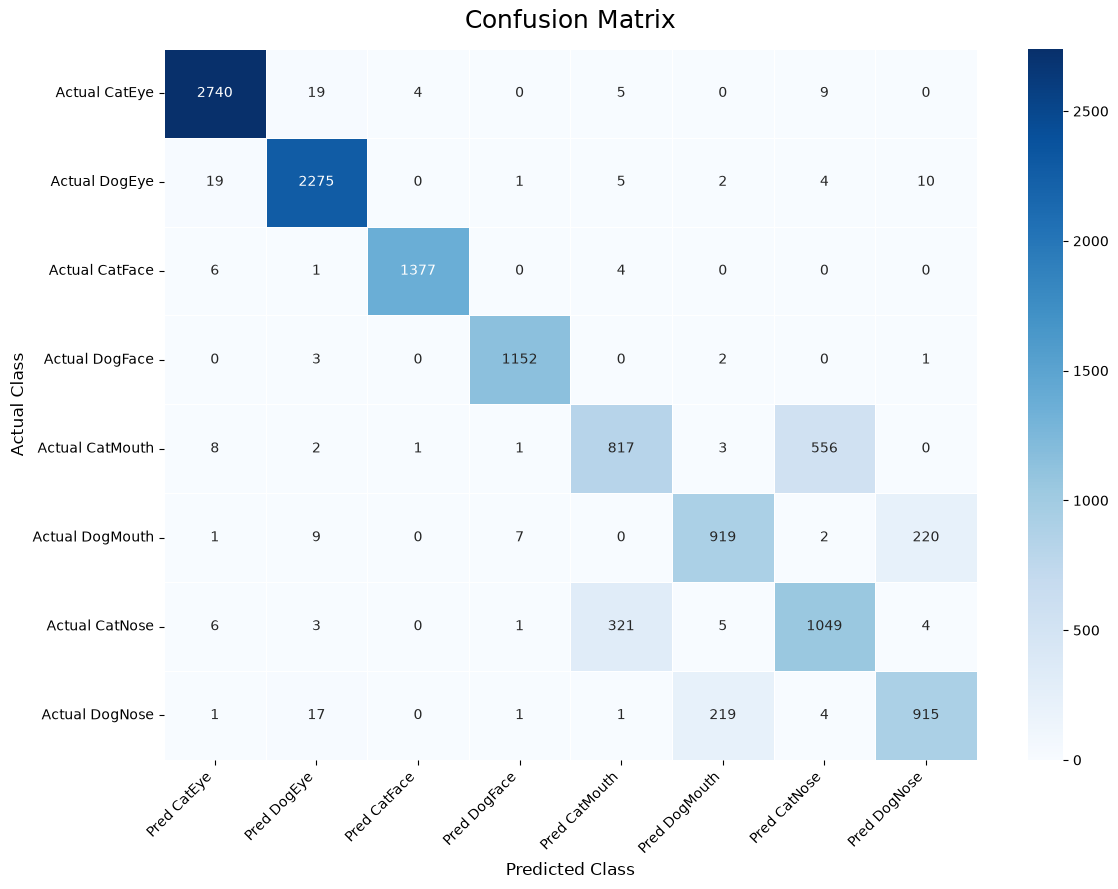

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Class labels
labels = [
    "CatEye",
    "DogEye",
    "CatFace",
    "DogFace",
    "CatMouth",
    "DogMouth",
    "CatNose",
    "DogNose"
]

# Confusion matrix
cm = np.array([
    [2740, 19,   4,   0,   5,   0,   9,   0],
    [19,   2275, 0,   1,   5,   2,   4,  10],
    [6,    1,   1377, 0,   4,   0,   0,   0],
    [0,    3,   0,   1152, 0,   2,   0,   1],
    [8,    2,   1,   1,   817, 3, 556, 0],
    [1,    9,   0,   7,   0,   919, 2, 220],
    [6,    3,   0,   1,   321, 5, 1049, 4],
    [1,    17,  0,   1,   1,   219, 4, 915]
])

# Convert to DataFrame for easier labeling
cm_df = pd.DataFrame(
    cm,
    index=[f"Actual {label}" for label in labels],
    columns=[f"Pred {label}" for label in labels]
)

# Plot
plt.figure(figsize=(12, 9))

sns.heatmap(
    cm_df,
    annot=True,       # Show values in cells
    fmt="d",          # Integer formatting
    cmap="Blues",
    linewidths=0.5,
    cbar=True
)

plt.title("Confusion Matrix", fontsize=18, pad=15)
plt.xlabel("Predicted Class", fontsize=12)
plt.ylabel("Actual Class", fontsize=12)

plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()

In [18]:
#Classify test set

import os
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision.models import vit_b_32, ViT_B_32_Weights
from PIL import Image
from tqdm import tqdm

test_images = r"C:\Users\wah31\OneDrive\Documents\Data_Ai_Kaggle\enge-707-2026-s-2-cat-and-dog-facial-feature-classification-ch\test\test"

model_path = r"C:\Users\wah31\OneDrive\Documents\Data_Ai_Kaggle\animal_facial_recognition\saved_models\best_vit_b32_classifier.pth"

output_csv = "vit_b32_test_predictions.csv"

class_names = [
    'CatEye',
    'DogEye',
    'CatFace',
    'DogFace',
    'CatMouth',
    'DogMouth',
    'CatNose',
    'DogNose'
]

weights = ViT_B_32_Weights.DEFAULT

transform = weights.transforms()

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Using device:", device)


class TestDataset(Dataset):

    def __init__(
        self,
        image_dir,
        transform=None
    ):
        self.image_dir = image_dir
        self.transform = transform

        self.image_files = [
            f for f in os.listdir(image_dir)
            if f.lower().endswith(
                (".jpg", ".jpeg", ".png")
            )
        ]

        self.image_files.sort()

    def __len__(self):
        return len(self.image_files)

    def __getitem__(self, idx):

        filename = self.image_files[idx]

        image_path = os.path.join(
            self.image_dir,
            filename
        )

        image = Image.open(
            image_path
        ).convert("RGB")

        if self.transform:
            image = self.transform(image)

        image_id = os.path.splitext(filename)[0]

        return image, image_id


test_dataset = TestDataset(
    test_images,
    transform=transform
)

test_loader = DataLoader(
    test_dataset,
    batch_size=16,
    shuffle=False,
    num_workers=0
)

print("Test images:", len(test_dataset))


vit = vit_b_32(
    weights=weights
)

vit.eval()

for param in vit.parameters():
    param.requires_grad = False

vit = vit.to(device)


classifier = nn.Linear(
    vit.heads.head.in_features,
    8
)

classifier.load_state_dict(
    torch.load(
        model_path,
        map_location=device
    )
)

classifier = classifier.to(device)

classifier.eval()


results = []

with torch.no_grad():

    for images, image_ids in tqdm(
        test_loader,
        desc="Predicting test images"
    ):

        images = images.to(device)

        features = vit._process_input(images)

        n = features.shape[0]

        batch_class_token = vit.class_token.expand(
            n,
            -1,
            -1
        )

        features = torch.cat(
            [batch_class_token, features],
            dim=1
        )

        features = vit.encoder(features)

        features = features[:, 0]

        outputs = classifier(features)

        probabilities = torch.softmax(
            outputs,
            dim=1
        )

        confidence, predicted = torch.max(
            probabilities,
            dim=1
        )

        for i in range(len(image_ids)):

            row = {
                "image_id": image_ids[i],
                "prediction": class_names[
                    predicted[i].item()
                ],
                "confidence": confidence[i].item()
            }

            for j, class_name in enumerate(class_names):

                row[
                    class_name + "_prob"
                ] = probabilities[
                    i, j
                ].item()

            results.append(row)


results_df = pd.DataFrame(results)

results_df.to_csv(
    output_csv,
    index=False
)

print()
print("Predictions saved to:")
print(output_csv)

print()
print(results_df.head())

Using device: cpu
Test images: 29443


Predicting test images: 100%|██████████| 1841/1841 [23:35<00:00,  1.30it/s]



Predictions saved to:
vit_b32_test_predictions.csv

  image_id prediction  confidence   CatEye_prob   DogEye_prob  CatFace_prob  \
0    00001     DogEye    0.999514  3.255166e-04  9.995145e-01  5.292712e-08   
1    00002   DogMouth    0.997672  4.858257e-11  1.353297e-08  6.764218e-11   
2    00003    DogNose    0.700230  7.755598e-05  5.511351e-03  2.243682e-06   
3    00004    DogFace    0.988293  1.007768e-03  2.153293e-03  6.125385e-06   
4    00005   CatMouth    0.733709  1.036635e-06  1.373588e-12  2.885448e-05   

   DogFace_prob  CatMouth_prob  DogMouth_prob  CatNose_prob  DogNose_prob  
0  3.277839e-05   3.432582e-05   5.162975e-05  5.154412e-06  3.620112e-05  
1  1.877749e-05   7.387766e-07   9.976725e-01  9.331692e-07  2.307092e-03  
2  6.730679e-07   4.381963e-05   2.940851e-01  4.874225e-05  7.002305e-01  
3  9.882930e-01   1.779170e-04   6.512599e-03  7.335500e-05  1.775935e-03  
4  7.048199e-11   7.337089e-01   1.243731e-07  2.662612e-01  1.081070e-08  


EfficientNet B0

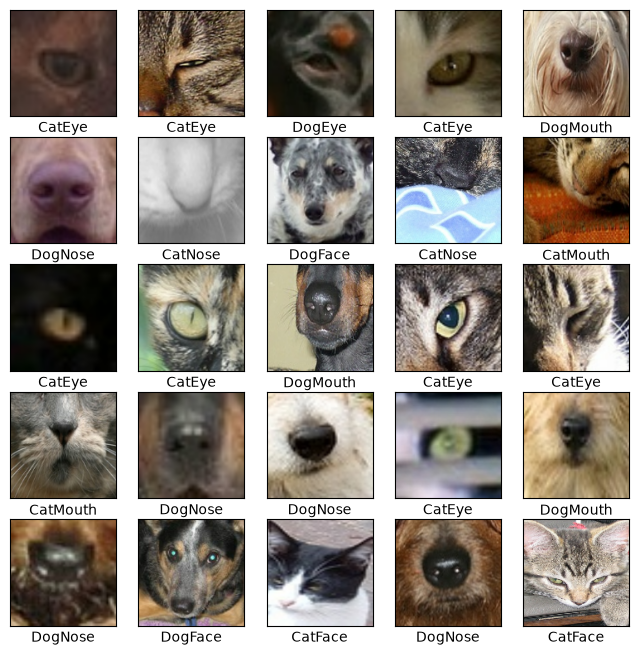

c:\Users\wah31\OneDrive\Documents\Data_Ai_Kaggle\venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


Epoch 1/30
1592/1592 ━━━━━━━━━━━━━━━━━━━━ 396s 236ms/step - accuracy: 0.8612 - loss: 0.3586 - val_accuracy: 0.9190 - val_loss: 0.2021 - learning_rate: 0.0010
Epoch 2/30
1592/1592 ━━━━━━━━━━━━━━━━━━━━ 357s 224ms/step - accuracy: 0.8979 - loss: 0.2633 - val_accuracy: 0.9298 - val_loss: 0.1761 - learning_rate: 0.0010
Epoch 3/30
1592/1592 ━━━━━━━━━━━━━━━━━━━━ 353s 222ms/step - accuracy: 0.9072 - loss: 0.2392 - val_accuracy: 0.9310 - val_loss: 0.1663 - learning_rate: 0.0010
Epoch 4/30
1592/1592 ━━━━━━━━━━━━━━━━━━━━ 341s 214ms/step - accuracy: 0.9095 - loss: 0.2313 - val_accuracy: 0.9343 - val_loss: 0.1616 - learning_rate: 0.0010
Epoch 5/30
1592/1592 ━━━━━━━━━━━━━━━━━━━━ 345s 217ms/step - accuracy: 0.9129 - loss: 0.2208 - val_accuracy: 0.9378 - val_loss: 0.1571 - learning_rate: 0.0010
Epoch 6/30
1592/1592 ━━━━━━━━━━━━━━━━━━━━ 365s 229ms/step - accuracy: 0.9163 - loss: 0.2143 - val_accuracy: 0.9384 - val_loss: 0.1554 - learning_rate: 0.0010
Epoch 7/30
1592/1592 ━━━━━━━━━━━━━━━━━━━━ 358s 225ms

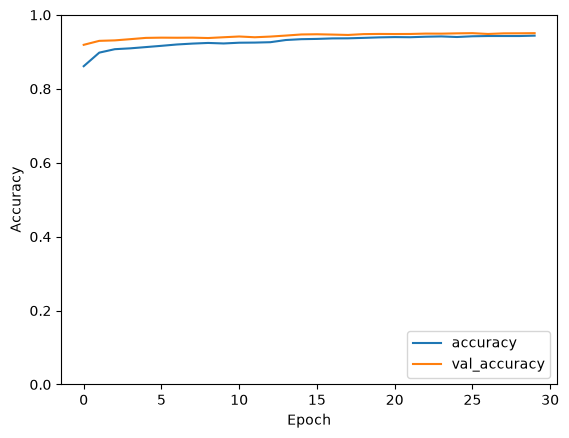

398/398 - 61s - 154ms/step - accuracy: 0.1091 - loss: 7.7468


AttributeError: 'numpy.ndarray' object has no attribute 'numpy'

In [8]:
# Import TensorFlow
import tensorflow as tf
from tensorflow.keras import layers, models
import matplotlib.pyplot as plt

import os
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from tensorflow.keras.utils import load_img, img_to_array

from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report,
    roc_curve,
    auc,
    roc_auc_score
)
from sklearn.preprocessing import label_binarize

#Load Data set 

label_csv = r"C:\Users\wah31\OneDrive\Documents\Data_Ai_Kaggle\animal_facial_recognition\train_labels.csv"
training_images = r"C:\Users\wah31\OneDrive\Documents\Data_Ai_Kaggle\enge-707-2026-s-2-cat-and-dog-facial-feature-classification-ch\train\train"


df = pd.read_csv(label_csv, dtype={'image_id': str})

class_names = [
    'CatEye',
    'DogEye',
    'CatFace',
    'DogFace',
    'CatMouth',
    'DogMouth',
    'CatNose',
    'DogNose'
]

class_to_number = {
    name: i for i, name in enumerate(class_names)
}

df['label'] = df['class'].map(class_to_number)

train_df, val_df = train_test_split(
    df,
    test_size=0.2,
    random_state=123,
    stratify=df['label']
)

IMAGE_SIZE = (128, 128)

def load_image(image_id, label):
    image_path = tf.strings.join([
        training_images,
        os.sep,
        image_id,
        '.jpg'
    ])

    image = tf.io.read_file(image_path)
    image = tf.image.decode_jpeg(image, channels=3)
    image = tf.image.resize(image, IMAGE_SIZE)
    #efficient net need pixels in 0-255 range
    #image = image / 255.0 

    return image, label

train_dataset = tf.data.Dataset.from_tensor_slices(
    (
        train_df['image_id'].values,
        train_df['label'].values
    )
)

validation_dataset = tf.data.Dataset.from_tensor_slices(
    (
        val_df['image_id'].values,
        val_df['label'].values
    )
)

train_dataset = train_dataset.map(
    load_image,
    num_parallel_calls=tf.data.AUTOTUNE
)

validation_dataset = validation_dataset.map(
    load_image,
    num_parallel_calls=tf.data.AUTOTUNE
)

BATCH_SIZE = 32

train_dataset = train_dataset.batch(BATCH_SIZE)
validation_dataset = validation_dataset.batch(BATCH_SIZE)

train_dataset = train_dataset.prefetch(tf.data.AUTOTUNE)
validation_dataset = validation_dataset.prefetch(tf.data.AUTOTUNE)

plt.figure(figsize=(8, 8))

for images, labels in train_dataset.take(1):
    for i in range(min(25, len(images))):
        plt.subplot(5, 5, i + 1)
        plt.xticks([])
        plt.yticks([])
        plt.grid(False)
        plt.imshow(images[i].numpy().astype(np.uint8))
        plt.xlabel(class_names[labels[i]])

plt.show()

data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.05),
    layers.RandomZoom(0.1),
    layers.RandomContrast(0.1),
])

base_model = tf.keras.applications.EfficientNetB0(
    include_top=False,
    weights='imagenet',
    input_shape=(128, 128, 3)
)

base_model.trainable = False

model = tf.keras.Sequential([
    data_augmentation,

    base_model,

    layers.GlobalAveragePooling2D(),

    layers.Dropout(0.3),

    layers.Dense(128, activation='relu'),

    layers.Dropout(0.2),

    layers.Dense(8, activation='softmax')
])

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)


callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor='val_loss',
        patience=3,
        restore_best_weights=True
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor='val_loss',
        factor=0.5,
        patience=2,
        min_lr=1e-6
    )
]

EPOCHS = 30

history = model.fit(
    train_dataset,
    epochs= EPOCHS,
    validation_data=validation_dataset,
    callbacks =callbacks
)

from datetime import datetime
timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")

model_save_path = (
    r"C:\Users\wah31\OneDrive\Documents\Data_Ai_Kaggle"
    r"\animal_facial_recognition\saved_models"
    rf"\EfficentNetB0_Base_{EPOCHS}_{timestamp}.keras"
)


model.save(model_save_path)

plt.plot(
    history.history['accuracy'],
    label='accuracy'
)

plt.plot(
    history.history['val_accuracy'],
    label='val_accuracy'
)

plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.ylim([0, 1])
plt.legend(loc='lower right')

plt.show()

test_loss, test_acc = model.evaluate(
    test_dataset,
    verbose=2
)
y_true = []
y_prob = []

for images, labels in test_dataset:

    probabilities =  model.predict(images, verbose=0)

    y_true.extend(labels.numpy())
    y_prob.extend(probabilities.numpy())

y_true = np.array(y_true)
y_prob = np.array(y_prob)

y_pred = np.argmax(
    y_prob,
    axis=1
)


# Find misclassified images
misclassified_indices = np.where(y_true != y_pred)[0]

# Reset index so it matches y_true and y_pred
test_results = test_df.reset_index(drop=True)

# Create a DataFrame containing the misclassified images
misclassified_df = pd.DataFrame({
    'image_id': test_results.iloc[misclassified_indices]['image_id'].values,
    'true_label': [
        class_names[i] for i in y_true[misclassified_indices]
    ],
    'predicted_label': [
        class_names[i] for i in y_pred[misclassified_indices]
    ]
})

# Export to CSV
misclassified_df.to_csv(
    'misclassified_image_ids.csv',
    index=False
)

print(
    f"Exported {len(misclassified_df)} misclassified images "
    f"to misclassified_image_ids.csv"
)



cm = confusion_matrix(
    y_true,
    y_pred
)

fig, ax = plt.subplots(
    figsize=(10, 8)
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

disp.plot(
    ax=ax,
    cmap='Blues',
    xticks_rotation=45
)

plt.title('Confusion Matrix')
plt.tight_layout()
plt.show()

print('\nClassification Report:\n')

print(
    classification_report(
        y_true,
        y_pred,
        target_names=class_names
    )
)

y_true_bin = label_binarize(
    y_true,
    classes=np.arange(len(class_names))
)

print('\nROC-AUC for Each Class:')

for i, class_name in enumerate(class_names):
    class_auc = roc_auc_score(
        y_true_bin[:, i],
        y_prob[:, i]
    )

    print(
        f'{class_name}: {class_auc:.4f}'
    )

overall_auc = roc_auc_score(
    y_true_bin,
    y_prob,
    multi_class='ovr',
    average='macro'
)

print(
    f'\nOverall ROC-AUC (Macro OvR): {overall_auc:.4f}'
)

plt.figure(figsize=(10, 8))

for i, class_name in enumerate(class_names):
    fpr, tpr, _ = roc_curve(
        y_true_bin[:, i],
        y_prob[:, i]
    )

    class_auc = auc(
        fpr,
        tpr
    )

    plt.plot(
        fpr,
        tpr,
        label=f'{class_name} (AUC = {class_auc:.3f})'
    )

plt.plot(
    [0, 1],
    [0, 1],
    linestyle='--',
    label='Random classifier'
)

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curves - One-vs-Rest')

plt.legend(
    loc='lower right',
    fontsize=9
)

plt.grid()
plt.tight_layout()
plt.show()
print('Test Accuracy is', test_acc)


In [2]:
#Testing

import tensorflow as tf
import numpy as np
import os
import pandas as pd
from tqdm import tqdm

model_path = r"C:\Users\wah31\OneDrive\Documents\Data_Ai_Kaggle\animal_facial_recognition\saved_models\EfficentNetB0_Base_30_20261008_200152.keras"

test_folder = r"C:\Users\wah31\OneDrive\Documents\Data_Ai_Kaggle\enge-707-2026-s-2-cat-and-dog-facial-feature-classification-ch\test\test"

model = tf.keras.models.load_model(model_path)

print("Model loaded successfully!")

BATCH_SIZE = 64
IMAGE_SIZE = (128 ,128)
class_names = [
    'CatEye',
    'DogEye',
    'CatFace',
    'DogFace',
    'CatMouth',
    'DogMouth',
    'CatNose',
    'DogNose'
]

print("Model output shape:", model.output_shape)
print("Model input shape:", model.input_shape)
print("Number of class names:", len(class_names))

def classify_folder(folder_path):

    results = []

    filenames = [
        filename
        for filename in os.listdir(folder_path)
        if filename.lower().endswith(
            ('.jpg', '.jpeg', '.png')
        )
    ]

    for i in tqdm(
        range(0, len(filenames), BATCH_SIZE),
        desc="Classifying images",
        unit="batch"
    ):

        batch_filenames = filenames[i:i + BATCH_SIZE]

        images = []

        for filename in batch_filenames:

            image_path = os.path.join(
                folder_path,
                filename
            )

            image = tf.io.read_file(image_path)

            image = tf.image.decode_image(
                image,
                channels=3,
                expand_animations=False
            )

            image = tf.image.resize(
                image,
                IMAGE_SIZE
            )

            #image = image / 255.0

            images.append(image)

        images = tf.stack(images)

        # Predict entire batch at once
        probabilities = model.predict(
            images,
            verbose=0
        )

        for filename, probability in zip(
            batch_filenames,
            probabilities
        ):

            predicted_index = np.argmax(probability)

            predicted_class = class_names[
                predicted_index
            ]

            confidence = probability[
                predicted_index
            ]

            results.append({
                'image_id': filename,
                'class': predicted_class,
                # 'confidence': confidence
            })

    results_df = pd.DataFrame(results)

    model_name = os.path.basename(model_path)
    output_folder = r"C:\Users\wah31\OneDrive\Documents\Data_Ai_Kaggle\animal_facial_recognition\test_results"
    output_path = os.path.join(
    output_folder,
    model_name.replace(".keras", "_results.csv")
    )

    results_df.to_csv(
        output_path,
        index=False
    )
    

    return results_df


classify_folder(test_folder)

Model loaded successfully!
Model output shape: (32, 8)
Model input shape: (32, 128, 128, 3)
Number of class names: 8


Classifying images: 100%|██████████| 461/461 [04:45<00:00,  1.61batch/s]


,image_id,class
0,00001.jpg,DogEye
1,00002.jpg,DogMouth
2,00003.jpg,DogNose
3,00004.jpg,DogFace
4,00005.jpg,CatMouth
...,...,...
29438,29439.jpg,CatNose
29439,29440.jpg,CatNose
29440,29441.jpg,DogFace
29441,29442.jpg,DogFace


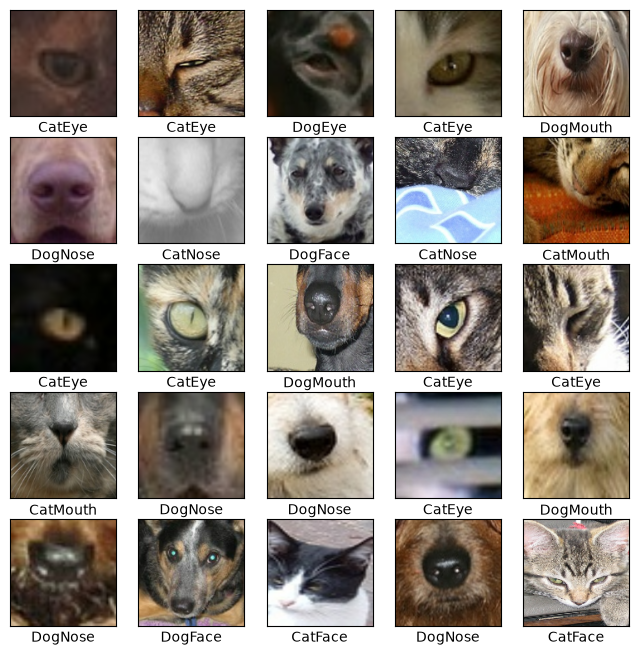

c:\Users\wah31\OneDrive\Documents\Data_Ai_Kaggle\venv\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential (Sequential)         │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

Epoch 1/30


c:\Users\wah31\OneDrive\Documents\Data_Ai_Kaggle\venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


1592/1592 ━━━━━━━━━━━━━━━━━━━━ 239s 149ms/step - accuracy: 0.4851 - loss: 1.3325 - val_accuracy: 0.7110 - val_loss: 0.7848 - learning_rate: 0.0010
Epoch 2/30
1592/1592 ━━━━━━━━━━━━━━━━━━━━ 262s 164ms/step - accuracy: 0.7134 - loss: 0.7630 - val_accuracy: 0.8088 - val_loss: 0.5297 - learning_rate: 0.0010
Epoch 3/30
1592/1592 ━━━━━━━━━━━━━━━━━━━━ 258s 162ms/step - accuracy: 0.7740 - loss: 0.6111 - val_accuracy: 0.8524 - val_loss: 0.4235 - learning_rate: 0.0010
Epoch 4/30
1592/1592 ━━━━━━━━━━━━━━━━━━━━ 275s 173ms/step - accuracy: 0.8110 - loss: 0.5217 - val_accuracy: 0.8773 - val_loss: 0.3571 - learning_rate: 0.0010
Epoch 5/30
1592/1592 ━━━━━━━━━━━━━━━━━━━━ 242s 152ms/step - accuracy: 0.8317 - loss: 0.4750 - val_accuracy: 0.8888 - val_loss: 0.3294 - learning_rate: 0.0010
Epoch 6/30
1592/1592 ━━━━━━━━━━━━━━━━━━━━ 276s 173ms/step - accuracy: 0.8398 - loss: 0.4490 - val_accuracy: 0.8784 - val_loss: 0.3589 - learning_rate: 0.0010
Epoch 7/30
1592/1592 ━━━━━━━━━━━━━━━━━━━━ 259s 163ms/step - acc

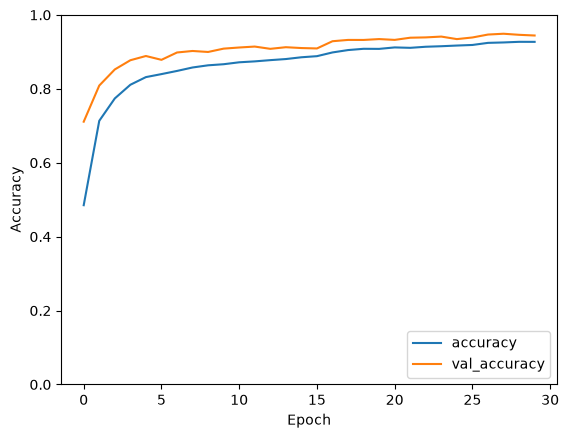

398/398 - 15s - 38ms/step - accuracy: 0.9490 - loss: 0.1544


AttributeError: 'numpy.ndarray' object has no attribute 'numpy'

In [ ]:
# Import TensorFlow
import tensorflow as tf
from tensorflow.keras import layers, models
import matplotlib.pyplot as plt

import os
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from tensorflow.keras.utils import load_img, img_to_array

from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report,
    roc_curve,
    auc,
    roc_auc_score
)
from sklearn.preprocessing import label_binarize

#Load Data set 

label_csv = r"C:\Users\wah31\OneDrive\Documents\Data_Ai_Kaggle\animal_facial_recognition\train_labels.csv"
training_images = r"C:\Users\wah31\OneDrive\Documents\Data_Ai_Kaggle\enge-707-2026-s-2-cat-and-dog-facial-feature-classification-ch\train\train"


df = pd.read_csv(label_csv, dtype={'image_id': str})

class_names = [
    'CatEye',
    'DogEye',
    'CatFace',
    'DogFace',
    'CatMouth',
    'DogMouth',
    'CatNose',
    'DogNose'
]

class_to_number = {
    name: i for i, name in enumerate(class_names)
}

df['label'] = df['class'].map(class_to_number)

train_df, test_df = train_test_split(
    df,
    test_size=0.2,
    random_state=123,
    stratify=df['label']
)

IMAGE_SIZE = (128, 128)

def load_image(image_id, label):
    image_path = tf.strings.join([
        training_images,
        os.sep,
        image_id,
        '.jpg'
    ])

    image = tf.io.read_file(image_path)
    image = tf.image.decode_jpeg(image, channels=3)
    image = tf.image.resize(image, IMAGE_SIZE)
    image = image / 255.0

    return image, label

train_dataset = tf.data.Dataset.from_tensor_slices(
    (
        train_df['image_id'].values,
        train_df['label'].values
    )
)

test_dataset = tf.data.Dataset.from_tensor_slices(
    (
        test_df['image_id'].values,
        test_df['label'].values
    )
)

train_dataset = train_dataset.map(
    load_image,
    num_parallel_calls=tf.data.AUTOTUNE
)

test_dataset = test_dataset.map(
    load_image,
    num_parallel_calls=tf.data.AUTOTUNE
)

BATCH_SIZE = 32

train_dataset = train_dataset.batch(BATCH_SIZE)
test_dataset = test_dataset.batch(BATCH_SIZE)

train_dataset = train_dataset.prefetch(tf.data.AUTOTUNE)
test_dataset = test_dataset.prefetch(tf.data.AUTOTUNE)

plt.figure(figsize=(8, 8))

for images, labels in train_dataset.take(1):
    for i in range(min(25, len(images))):
        plt.subplot(5, 5, i + 1)
        plt.xticks([])
        plt.yticks([])
        plt.grid(False)
        plt.imshow(images[i])
        plt.xlabel(class_names[labels[i]])

plt.show()

data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.4),
    layers.RandomZoom(0.1),
    layers.RandomContrast(0.1),
])


model = models.Sequential([

    data_augmentation,
    layers.Conv2D(32,(3, 3),activation='relu',input_shape=(128, 128, 3)),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64,(3, 3),activation='relu'),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64,(3, 3),activation='relu'),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64,(3, 3),activation='relu'),

    layers.Flatten(),
    layers.Dense(64,activation='relu'),
    layers.Dropout(0.3),

    layers.Dense(8, activation='softmax')
])

model.summary()

model.compile(
    optimizer='adam',
    loss=tf.keras.losses.SparseCategoricalCrossentropy(
        from_logits=False
    ),
    metrics=['accuracy']
)

callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor='val_loss',
        patience=3,
        restore_best_weights=True
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor='val_loss',
        factor=0.5,
        patience=2,
        min_lr=1e-6
    )
]

EPOCHS = 30

history = model.fit(
    train_dataset,
    epochs= EPOCHS,
    validation_data=test_dataset,
    callbacks =callbacks
)

from datetime import datetime
timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")

model_save_path = (
    r"C:\Users\wah31\OneDrive\Documents\Data_Ai_Kaggle"
    r"\animal_facial_recognition\saved_models"
    rf"\CNN_Base_{EPOCHS}_{timestamp}.keras"
)


model.save(model_save_path)

plt.plot(
    history.history['accuracy'],
    label='accuracy'
)

plt.plot(
    history.history['val_accuracy'],
    label='val_accuracy'
)

plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.ylim([0, 1])
plt.legend(loc='lower right')

plt.show()

test_loss, test_acc = model.evaluate(
    test_dataset,
    verbose=2
)
y_true = []
y_prob = []

for images, labels in test_dataset:

    probabilities =  model.predict(images, verbose=0)

    y_true.extend(labels.numpy())
    y_prob.extend(probabilities)

y_true = np.array(y_true)
y_prob = np.array(y_prob)

y_pred = np.argmax(
    y_prob,
    axis=1
)


# Find misclassified images
misclassified_indices = np.where(y_true != y_pred)[0]

# Reset index so it matches y_true and y_pred
test_results = test_df.reset_index(drop=True)

# Create a DataFrame containing the misclassified images
misclassified_df = pd.DataFrame({
    'image_id': test_results.iloc[misclassified_indices]['image_id'].values,
    'true_label': [
        class_names[i] for i in y_true[misclassified_indices]
    ],
    'predicted_label': [
        class_names[i] for i in y_pred[misclassified_indices]
    ]
})

# Export to CSV
misclassified_df.to_csv(
    'misclassified_image_ids.csv',
    index=False
)

print(
    f"Exported {len(misclassified_df)} misclassified images "
    f"to misclassified_image_ids.csv"
)



cm = confusion_matrix(
    y_true,
    y_pred
)

fig, ax = plt.subplots(
    figsize=(10, 8)
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

disp.plot(
    ax=ax,
    cmap='Blues',
    xticks_rotation=45
)

plt.title('Confusion Matrix')
plt.tight_layout()
plt.show()

print('\nClassification Report:\n')

print(
    classification_report(
        y_true,
        y_pred,
        target_names=class_names
    )
)

y_true_bin = label_binarize(
    y_true,
    classes=np.arange(len(class_names))
)

print('\nROC-AUC for Each Class:')

for i, class_name in enumerate(class_names):
    class_auc = roc_auc_score(
        y_true_bin[:, i],
        y_prob[:, i]
    )

    print(
        f'{class_name}: {class_auc:.4f}'
    )

overall_auc = roc_auc_score(
    y_true_bin,
    y_prob,
    multi_class='ovr',
    average='macro'
)

print(
    f'\nOverall ROC-AUC (Macro OvR): {overall_auc:.4f}'
)

plt.figure(figsize=(10, 8))

for i, class_name in enumerate(class_names):
    fpr, tpr, _ = roc_curve(
        y_true_bin[:, i],
        y_prob[:, i]
    )

    class_auc = auc(
        fpr,
        tpr
    )

    plt.plot(
        fpr,
        tpr,
        label=f'{class_name} (AUC = {class_auc:.3f})'
    )

plt.plot(
    [0, 1],
    [0, 1],
    linestyle='--',
    label='Random classifier'
)

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curves - One-vs-Rest')

plt.legend(
    loc='lower right',
    fontsize=9
)

plt.grid()
plt.tight_layout()
plt.show()
print('Test Accuracy is', test_acc)


In [2]:
#testing data

import tensorflow as tf
import numpy as np
import os
import pandas as pd
from tqdm import tqdm

model_path = r"C:\Users\wah31\OneDrive\Documents\Data_Ai_Kaggle\animal_facial_recognition\saved_models\CNN_Base_30_20261012_105702.keras"

test_folder = r"C:\Users\wah31\OneDrive\Documents\Data_Ai_Kaggle\enge-707-2026-s-2-cat-and-dog-facial-feature-classification-ch\test\test"

model = tf.keras.models.load_model(model_path)

print("Model loaded successfully!")

BATCH_SIZE = 64


def classify_folder(folder_path):

    results = []

    filenames = [
        filename
        for filename in os.listdir(folder_path)
        if filename.lower().endswith(
            ('.jpg', '.jpeg', '.png')
        )
    ]

    for i in tqdm(
        range(0, len(filenames), BATCH_SIZE),
        desc="Classifying images",
        unit="batch"
    ):

        batch_filenames = filenames[i:i + BATCH_SIZE]

        images = []

        for filename in batch_filenames:

            image_path = os.path.join(
                folder_path,
                filename
            )

            image = tf.io.read_file(image_path)

            image = tf.image.decode_image(
                image,
                channels=3,
                expand_animations=False
            )

            image = tf.image.resize(
                image,
                IMAGE_SIZE
            )

            image = image / 255.0

            images.append(image)

        images = tf.stack(images)

        # Predict entire batch at once
        probabilities = model.predict(
            images,
            verbose=0
        )

        for filename, probability in zip(
            batch_filenames,
            probabilities
        ):

            predicted_index = np.argmax(probability)

            predicted_class = class_names[
                predicted_index
            ]

            confidence = probability[
                predicted_index
            ]

            results.append({
                'image_id': os.path.splitext(filename)[0],
                'class': predicted_class,
                # 'confidence': confidence
            })

    results_df = pd.DataFrame(results)

    model_name = os.path.basename(model_path)
    output_folder = r"C:\Users\wah31\OneDrive\Documents\Data_Ai_Kaggle\animal_facial_recognition\test_results"
    output_path = os.path.join(
    output_folder,
    model_name.replace(".keras", "_results.csv")
    )

    results_df.to_csv(
        output_path,
        index=False
    )
    

    return results_df


classify_folder(test_folder)

Model loaded successfully!


Classifying images: 100%|██████████| 461/461 [02:56<00:00,  2.61batch/s]


,image_id,class
0,00001,DogEye
1,00002,DogMouth
2,00003,DogNose
3,00004,DogFace
4,00005,CatMouth
...,...,...
29438,29439,DogEye
29439,29440,CatNose
29440,29441,DogFace
29441,29442,DogFace
